# Layered media: spatial dispersion in closed form

Notebooks 01 to 04 asked what part of the second-order spatial dispersion of a structured medium is a permeability, and answered it for a lattice of dielectric rods, where every number rests on a multipole expansion and a lattice sum. A periodic stack of layers is the simplest nonlocal medium there is. The source-driven problem is an ordinary differential equation with constant coefficients inside each layer, so $\varepsilon(\omega,\mathbf k)$ is exact to rounding for any complex $\omega$ and $\mathbf k$, and the Bloch waves come from a $2\times2$ transfer matrix. That makes the stack an exact test case for the kind of statement made about rods (the Taylor coefficients, the permeability projection and the Bloch admittance); what carries over to the two-dimensional lattice is the shape of the argument, not a computation, and it also contains the best-known case of strong nonlocality in optics, the metal-dielectric multilayer near an epsilon-near-zero (ENZ) point, which has nothing to do with magnetism.

## What this notebook shows

- The exact $\varepsilon(\omega,\mathbf k)$ of a stack, from matrix exponentials, with five kinds of check: the static limit, the Bloch condition, direct against Maxwell-averaged fields, a second solver built from plane waves and $e^{\pm iqx}$, and symmetry and reciprocity.
- For the dielectric stack of notebook 01 (permittivity 12, thickness $0.3\,a$, and vacuum): the bulk permeability that the $k^2$ coefficient gives for $\mathbf E$ along the layers and $\mathbf k$ normal to them. Its deviation from one starts at order $\omega^4$ (the $\omega^2$ term vanishes), for the same reason as for TM rods in notebook 03, and the coefficient is a closed form; for $\mathbf k$ along the layers the same tensor component, read through $B$, is of order $\omega^2$. The second-order index correction is the same number from the Taylor coefficients, from the exact Bloch relation, and from a closed form that has the shape of Rytov's 1956 result.
- The five second-order coefficients that the symmetry of a stack allows for $\mathbf E$ in the plane, and the one combination of them that is a permeability.
- The Bloch admittance of the two symmetric cuts against the bulk admittance, in closed form. The coefficient of $(qa)^2$ is a closed form in the thickness and permittivity of the layer. Its lumped-circuit limit is $1/12$ for one cut and $-1/6$ for the other when the reference is the Bloch index, not $\pm1/8$, which bears on the comparison made for the rod lattice in notebook 04.
- A Drude-metal multilayer with a silver-like plasma frequency, around its ENZ frequency (a model stack, not a silver design: see the caveats): how far in $k_y$ the local effective medium with the exact $\varepsilon(\omega,0)$ holds at $a/\lambda_0<0.1$, how the second-order tensor does (for $f\le1.1\,f_{\rm ENZ}$ it reaches further than that local model, by a factor that depends on frequency; the comparison is against one local model only), and how large and how magnetic its coefficients are there.

## Conventions

As in notebooks 01 to 04: $e^{-i\omega t}$, $\varepsilon_0=\mu_0=c=1$ so $\omega=k_0$, lengths in units of the period $a=1$, and $f=a/\lambda_0=k_0/2\pi$ is the frequency and nothing else. The layers are stacked along $x$ and uniform in $y$ and $z$; $\mathbf k=(k_x,k_y)$ lies in the $x$-$y$ plane. TM means $\mathbf E=E_z\hat z$ (parallel to every layer, "s polarization"); TE means $\mathbf H=H_z\hat z$, with $E_x$ normal to the layers ("p polarization"). The local effective-medium values are $\langle\varepsilon\rangle$ for $\mathbf E$ along the layers and $1/\langle1/\varepsilon\rangle$ for $\mathbf E$ normal to them. $\eta$ is the thickness fraction of the first layer. `layered.py` in this folder holds the solver.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # layered.py sits next to this notebook
import layered as lay
from scipy.optimize import brentq
from itertools import product

TWO_PI = 2 * np.pi
ETA, EPS_R = 0.3, 12.0                                # the stack of notebook 01, section 5.2
STACK = [(ETA, EPS_R), (1 - ETA, 1.0)]
EPS_PAR, EPS_PERP = [v.real for v in lay.local_eps(STACK)]
print(f"stack: layer of permittivity {EPS_R:g} and thickness {ETA}, vacuum {1 - ETA:.1f}; <eps> = {EPS_PAR:.4f}, 1/<1/eps> = {EPS_PERP:.5f}")

def canon(z):
    """Wavenumber on the branch that decays or propagates toward +x: Im >= 0, and Re >= 0 when Im = 0."""
    z = complex(z)
    return -z if (z.imag < -1e-12 or (abs(z.imag) <= 1e-12 and z.real < 0)) else z

stack: layer of permittivity 12 and thickness 0.3, vacuum 0.7; <eps> = 4.3000, 1/<1/eps> = 1.37931


## 1. The driven stack

Drive the stack with an external current $\mathbf J_0e^{i(k_xx+k_yy)}$ that fills all space, as in notebook 03, and define $\varepsilon(\omega,\mathbf k)=1+\langle\mathbf P\rangle/\langle\mathbf E\rangle$ from the $e^{i\mathbf k\cdot\mathbf r}$ Fourier components over a cell. Write the field as $e^{ik_xx}$ times a periodic function $u(x)$. In a layer of permittivity $\varepsilon_j$:

- **TM.** $E_z=u\,e^{ik_xx}$ and $u''+2ik_xu'+(k_0^2\varepsilon_j-k^2)u=-ik_0J_0$. The field and its derivative are continuous at the interfaces.
- **TE.** $H_z=u\,e^{ik_xx}$ obeys $H_z''+q_j^2H_z=i(k_yJ_x-k_xJ_y)e^{ik_xx}$ with $q_j^2=k_0^2\varepsilon_j-k_y^2$. The conditions are continuity of $H_z$ and of $(H_z'+J_y)/\varepsilon$, which is $E_y$ up to a constant factor (the source appears in the second condition because the current carries the discontinuity of $\varepsilon$ with it; both conditions follow from continuity of the tangential $\mathbf E$ and $\mathbf H$). $E_x$ is then $\frac{i}{k_0\varepsilon}(ik_yH_z-J_x)$ and $E_y=-\frac{i}{k_0\varepsilon}(H_z'+J_y)$.

Each layer is a linear system with constant coefficients and a constant source, so the state (the field, its flux, the running integrals that give the averages $\langle\mathbf E\rangle$ and $\langle\mathbf P\rangle$, and the number 1) is propagated by one matrix exponential of an augmented matrix. The Bloch condition on the periodic part, $u(a)=u(0)$ and $u'(a)=u'(0)$, is a $2\times2$ linear system. Nothing is truncated. For TE two sources, along and across $\mathbf k$, give the $2\times2$ tensor in $x$-$y$ components, as in `rodlattice.driven`.

Averaging Maxwell's equations with the same weight gives $\mathbf k\times(\mathbf k\times\langle\mathbf E\rangle)+k_0^2\langle\mathbf E\rangle+k_0^2\langle\mathbf P\rangle=-ik_0\mathbf J_0$, which is a second route to $\langle\mathbf E\rangle$ that does not use the field inside the layers. `layered.driven_layered_modes` solves the same problem a different way, as a particular plane wave plus $e^{\pm iq_jx}$ in every layer with a $2N\times2N$ system for the amplitudes. It shares only the equations with the first solver, not the algebra.

**Checks.** (a) The static limit; (b) the Bloch condition; (c) the two averages of $\langle\mathbf E\rangle$ and the two solvers; (d) the two polarizations at $k_y=0$; (e) reality, symmetry and reciprocity.

In [3]:
# (a) static limit: f -> 0 and k -> 0
f_st, kk = 1e-6, 1e-3
worst_te = max(np.abs(lay.driven_layered(TWO_PI * f_st, *kv, STACK, "TE") - np.diag([EPS_PERP, EPS_PAR])).max() / EPS_PAR
               for kv in [(kk, 0.0), (0.0, kk), (kk / np.sqrt(2), kk / np.sqrt(2))])
worst_tm = max(abs(lay.driven_layered(TWO_PI * f_st, *kv, STACK, "TM") - EPS_PAR) / EPS_PAR for kv in [(kk, 0.0), (0.0, kk), (kk, kk)])
print(f"static limit (f = {f_st:g}, |k| = {kk:g}): TE tensor against diag(1/<1/eps>, <eps>): {worst_te:.1e}; TM against <eps>: {worst_tm:.1e}")
check("static limit, TE: diag(1/<1/eps>, <eps>) in three directions of k (max relative error)", worst_te, 1e-7)
check("static limit, TM: <eps> in three directions of k (max relative error)", worst_tm, 1e-7)
check("a homogeneous stack (both layers 4.0) has eps = 4 I at an oblique complex k (max error, TE and TM)",
      max(np.abs(lay.driven_layered(0.7, 0.4 + 0.2j, 0.9, [(0.3, 4.0), (0.7, 4.0)], "TE") - 4 * np.eye(2)).max(),
          abs(lay.driven_layered(0.7, 0.4 + 0.2j, 0.9, [(0.3, 4.0), (0.7, 4.0)], "TM") - 4)), 1e-12)

static limit (f = 1e-06, |k| = 0.001): TE tensor against diag(1/<1/eps>, <eps>): 7.5e-08; TM against <eps>: 4.1e-12
PASS  static limit, TE: diag(1/<1/eps>, <eps>) in three directions of k (max relative error): got 7.49702e-08, target 0, |diff| 7.50e-08 <= 1e-07
PASS  static limit, TM: <eps> in three directions of k (max relative error): got 4.08273e-12, target 0, |diff| 4.08e-12 <= 1e-07
PASS  a homogeneous stack (both layers 4.0) has eps = 4 I at an oblique complex k (max error, TE and TM): got 4.45843e-16, target 0, |diff| 4.46e-16 <= 1e-12


In [4]:
# (b) the Bloch condition: the exact free wave k_x of the transfer matrix is a zero of the driven dispersion function
def bloch_root_gap(f, ky, pol):
    k0 = TWO_PI * f
    kB = lay.bloch_kx(k0, ky, STACK, pol)
    assert abs(kB.imag) < 1e-12 and 0 < kB.real < np.pi, "chosen points are in the first pass band"
    kB = kB.real
    def fun(kx):
        e = lay.driven_layered(k0, kx, ky, STACK, pol)
        k2 = kx * kx + ky * ky
        if pol == "TM":
            return (k2 - k0 ** 2 * e).real                                      # k^2 = k0^2 eps_zz
        return np.linalg.det(k0 ** 2 * e - (k2 * np.eye(2) - np.array([[kx * kx, kx * ky], [kx * ky, ky * ky]]))).real
    return abs(brentq(fun, kB - 2e-3, kB + 2e-3, xtol=1e-14) - kB), kB

print("pol    f      k_y     k_x (transfer matrix)   |root of the driven condition - k_x|")
gaps = {}
for pol in ("TM", "TE"):
    for f, ky in [(0.08, 0.0), (0.10, 0.3), (0.12, 0.5), (0.14, 0.6)]:
        g, kB = bloch_root_gap(f, ky, pol)
        gaps[(pol, f)] = g
        print(f"{pol}  {f:5.2f}  {ky:5.2f}   {kB:18.12f}   {g:.1e}")
check("TM: k^2 = k0^2 eps_zz(w, k) at the Bloch wavenumber, normal and oblique (max gap in k_x)", max(v for (p, _), v in gaps.items() if p == "TM"), 1e-9)
check("TE: det[k0^2 eps(w, k) - (k^2 I - k k^T)] = 0 at the Bloch wavenumber, normal and oblique (max gap in k_x)", max(v for (p, _), v in gaps.items() if p == "TE"), 1e-7)

pol    f      k_y     k_x (transfer matrix)   |root of the driven condition - k_x|
TM   0.08   0.00       1.057690376982   2.2e-16
TM   0.10   0.30       1.300841936862   2.2e-16
TM   0.12   0.50       1.544941935411   2.2e-16
TM   0.14   0.60       1.837574920198   6.7e-16
TE   0.08   0.00       1.057690376982   2.2e-16
TE   0.10   0.30       1.209725188353   2.1e-09
TE   0.12   0.50       1.308778272115   4.3e-09
TE   0.14   0.60       1.513367816950   4.6e-09
PASS  TM: k^2 = k0^2 eps_zz(w, k) at the Bloch wavenumber, normal and oblique (max gap in k_x): got 6.66134e-16, target 0, |diff| 6.66e-16 <= 1e-09
PASS  TE: det[k0^2 eps(w, k) - (k^2 I - k k^T)] = 0 at the Bloch wavenumber, normal and oblique (max gap in k_x): got 4.56528e-09, target 0, |diff| 4.57e-09 <= 1e-07


At an oblique angle the TE tensor cannot be evaluated *at* the Bloch wavenumber, only around it: there the driven problem is resonant (the $2\times2$ system for the amplitudes is singular, because a free wave exists) and the two columns of the tensor inversion are parallel. So the check above finds the zero of the determinant between two points a few times $10^{-3}$ on either side and compares it with the transfer-matrix value. The TM check is not ill conditioned in the same way, since the ratio $\langle P\rangle/\langle E\rangle$ stays finite.

In [5]:
# (c) the two averages of <E>, and the two solvers, at random complex points with random complex layers
rng = np.random.default_rng(5)
dev_E, dev_solver = [], []
for _ in range(12):
    ds = rng.uniform(0.2, 0.8, 3); ds /= ds.sum()
    rand_layers = [(d, complex(rng.uniform(-3, 9), rng.uniform(0, 1))) for d in ds]
    k0, kx, ky = 0.3 + 2 * rng.random() + 0.1j * rng.normal(), rng.normal(size=2) @ [1, 0] + 0.2j * rng.normal(), rng.normal() + 0.2j * rng.normal()
    for pol in ("TM", "TE"):
        e1, info = lay.driven_layered(k0, kx, ky, rand_layers, pol, info=True)
        e2 = lay.driven_layered_modes(k0, kx, ky, rand_layers, pol)
        dev_E.append(np.abs(info["E_direct"] - info["E_maxwell"]).max() / np.abs(info["E_direct"]).max())
        dev_solver.append(np.abs(e1 - e2).max() / np.abs(e1).max())
print(f"24 random complex points (3 layers of random complex permittivity, complex k0, kx, ky): "
      f"direct against Maxwell-averaged <E> {max(dev_E):.1e}, matrix-exponential solver against plane-wave solver {max(dev_solver):.1e}")
check("direct and Maxwell-averaged <E> agree (max relative difference)", max(dev_E), 1e-9)
check("matrix-exponential solver and plane-wave solver agree (max relative difference)", max(dev_solver), 1e-9)

# (d) at k_y = 0 the two polarizations see E tangential to the layers
dev_d = max(abs(lay.driven_layered(TWO_PI * f, kx, 0.0, STACK, "TM") - lay.driven_layered(TWO_PI * f, kx, 0.0, STACK, "TE")[1, 1])
            for f in (0.03, 0.08, 0.15) for kx in (0.2, 0.9, 1.7))
check("at k_y = 0, TM eps_zz equals TE eps_yy (max difference over nine points)", dev_d, 1e-11)

# (e) lossless: real, symmetric tensor; reciprocity eps(k) = eps(-k)^T, also with loss
worst_real = worst_sym = worst_rec = worst_rec_loss = 0.0
lossy = [(0.3, 12.0 + 1.5j), (0.7, 1.0 + 0.05j)]
for f, kx, ky in [(0.05, 0.4, 0.7), (0.1, 1.1, 0.3), (0.15, 0.7, 1.9), (0.07, -0.9, 0.5)]:
    k0 = TWO_PI * f
    e = lay.driven_layered(k0, kx, ky, STACK, "TE")
    worst_real = max(worst_real, np.abs(e.imag).max())
    worst_sym = max(worst_sym, np.abs(e - e.T).max())
    worst_rec = max(worst_rec, np.abs(e - lay.driven_layered(k0, -kx, -ky, STACK, "TE").T).max())
    el = lay.driven_layered(k0, kx, ky, lossy, "TE")
    worst_rec_loss = max(worst_rec_loss, np.abs(el - lay.driven_layered(k0, -kx, -ky, lossy, "TE").T).max())
check("lossless: eps(w, k) is real (max imaginary part)", worst_real, 1e-11)
check("lossless: eps(w, k) is symmetric (max |eps - eps^T|)", worst_sym, 1e-11)
check("eps(w, k) = eps(w, -k)^T (max error, lossless)", worst_rec, 1e-11)
check("eps(w, k) = eps(w, -k)^T with loss (max error; the loss keeps reciprocity but removes symmetry)", worst_rec_loss, 1e-11)
print(f"with loss: max |eps - eps^T| = {max(np.abs(lay.driven_layered(0.6, 0.4, 0.7, lossy, 'TE') - lay.driven_layered(0.6, 0.4, 0.7, lossy, 'TE').T).max(), 0):.2e}")

24 random complex points (3 layers of random complex permittivity, complex k0, kx, ky): direct against Maxwell-averaged <E> 5.5e-15, matrix-exponential solver against plane-wave solver 1.4e-15
PASS  direct and Maxwell-averaged <E> agree (max relative difference): got 5.50444e-15, target 0, |diff| 5.50e-15 <= 1e-09
PASS  matrix-exponential solver and plane-wave solver agree (max relative difference): got 1.38447e-15, target 0, |diff| 1.38e-15 <= 1e-09
PASS  at k_y = 0, TM eps_zz equals TE eps_yy (max difference over nine points): got 1.85115e-15, target 0, |diff| 1.85e-15 <= 1e-11
PASS  lossless: eps(w, k) is real (max imaginary part): got 8.50338e-16, target 0, |diff| 8.50e-16 <= 1e-11
PASS  lossless: eps(w, k) is symmetric (max |eps - eps^T|): got 1.01509e-15, target 0, |diff| 1.02e-15 <= 1e-11
PASS  eps(w, k) = eps(w, -k)^T (max error, lossless): got 8.18475e-16, target 0, |diff| 8.18e-16 <= 1e-11
PASS  eps(w, k) = eps(w, -k)^T with loss (max error; the loss keeps reciprocity but rem

The solver passes all five. The two solvers agree to rounding on random complex media, which a shared mistake in the equations would not show; the equations themselves are tested by the Bloch condition (the transfer matrix uses $H_z$ and $H_z'/\varepsilon$, the driven solver uses the source-dependent flux), by the static limit, and by the exact statement in section 2.3 that $\varepsilon_{xx}=1/\langle1/\varepsilon\rangle$ for $\mathbf k\parallel\hat x$.

## 2. The dielectric stack: where the bulk permeability goes

### 2.1 TM, $\mathbf E$ along the layers: the $k_x^2$ coefficient vanishes at low frequency

Take $\mathbf k=(\kappa,0)$, so that $\mathbf H$ is along $y$ and the coefficient of $\kappa^2$ is $\tau$ with $1/\mu_{yy}=1-k_0^2\tau$ (notebook 01: in TM every second-order term has the form of a permeability). For $k_y=0$ the equation is $E''+k_0^2\varepsilon(x)E=-ik_0J_0e^{i\kappa x}$. At $k_0=0$ with $\kappa$ fixed its solution is the plane wave $E=ik_0J_0e^{i\kappa x}/\kappa^2$, which does not see the layers: $\langle P\rangle/\langle E\rangle=\langle\varepsilon\rangle-1$ whatever $\kappa$ is. So $\varepsilon_{zz}(\omega,\kappa)$ is independent of $\kappa$ at order $k_0^0$, the $\kappa^2$ coefficient starts at order $k_0^2$, and $1-1/\mu=k_0^2\tau$ starts at order $k_0^4$. The same argument holds for TM rods in notebook 03, section 6, for any cross-section. Here it can be tested in two variables at once: a Cauchy integral over circles in the complex planes of both $k_0$ and $\kappa$ gives the double Taylor coefficients $c_{ij}$ of $\varepsilon_{zz}=\sum c_{ij}k_0^i\kappa^j$.

In [6]:
def cauchy2(fun, r1, r2, n=16, m=5):
    """Double Taylor coefficients c[i, j] (of z1^i z2^j) of an analytic function from n x n samples on two circles."""
    th = (np.arange(n) + 0.5) * TWO_PI / n
    V = np.array([[fun(r1 * np.exp(1j * a), r2 * np.exp(1j * b)) for b in th] for a in th])
    return np.array([[(V * np.exp(-1j * i * th)[:, None] * np.exp(-1j * j * th)[None, :]).mean() / r1 ** i / r2 ** j for j in range(m)] for i in range(m)])

tm_fun = lambda k0, kap: lay.driven_layered(k0, kap, 0.0, STACK, "TM")
c_a, c_b = cauchy2(tm_fun, 0.1, 0.1), cauchy2(tm_fun, 0.2, 0.3)
print("double Taylor coefficients c_ij of eps_zz(k0, kappa) along x, (i, j) = (0,0), (2,0), (0,2), (2,2):")
for nm, c in (("radii 0.1, 0.1", c_a), ("radii 0.2, 0.3", c_b)):
    print(f"  {nm}: {c[0, 0].real:.10f}  {c[2, 0].real:.10f}  {c[0, 2].real:+.2e}  {c[2, 2].real:.10f}   (largest imaginary part {np.abs(c.imag).max():.1e})")
check("the double coefficients do not depend on the radii of the circles (c_22, relative)", c_a[2, 2].real / c_b[2, 2].real - 1, 1e-8)
check("c_00 equals <eps>", c_b[0, 0].real, 1e-10, EPS_PAR)
check("c_02 = 0: no kappa^2 term at order k0^0 (the plane-wave argument)", abs(c_b[0, 2]), 1e-10)
print(f"c_22 = {c_b[2, 2].real:.10f} is the first kappa^2 coefficient: tau = c_22 k0^2, so mu_yy - 1 = c_22 (k0 a)^4 = {c_b[2, 2].real * TWO_PI**4:.3f} f^4")

# the coefficient as a function of frequency, and its scaling
F_TM = np.array([0.2, 0.1, 0.05, 0.025, 0.0125, 0.00625])
tm_tab = [lay.tm_second_order(TWO_PI * f, STACK, 0.3) for f in F_TM]
print("\n     f      eps(w, 0)     tau_x = coeff of kx^2   tau_x / f^2    mu_yy - 1    (mu_yy - 1)/f^4   coeff of ky^2   /f^2")
for f, r in zip(F_TM, tm_tab):
    k0 = TWO_PI * f
    mu_yy = 1 / (1 - k0 ** 2 * r["cx"].real)
    print(f"{f:8.5f} {r['eps0'].real:11.6f} {r['cx'].real:20.8e} {r['cx'].real / f**2:13.6f} {mu_yy - 1:12.4e} {(mu_yy - 1) / f**4:14.4f} {r['cy'].real:16.6e} {r['cy'].real / f**2:9.5f}")
slope = np.log(tm_tab[-1]["cx"].real / tm_tab[-2]["cx"].real) / np.log(F_TM[-1] / F_TM[-2])
check("tau_x scales like f^2 (exponent between the two lowest frequencies)", slope, 0.01, 2.0)
check("tau_x / k0^2 at the lowest frequency against c_22 (relative)", tm_tab[-1]["cx"].real / (TWO_PI * F_TM[-1]) ** 2 / c_b[2, 2].real - 1, 5e-3)
slope_y = np.log(tm_tab[-1]["cy"].real / tm_tab[-2]["cy"].real) / np.log(F_TM[-1] / F_TM[-2])
check("the k_y^2 coefficient (H normal to the layers) also scales like f^2", slope_y, 0.01, 2.0)

double Taylor coefficients c_ij of eps_zz(k0, kappa) along x, (i, j) = (0,0), (2,0), (0,2), (2,2):
  radii 0.1, 0.1: 4.3000000000  0.4446750000  -3.70e-14  0.0315719250   (largest imaginary part 1.1e-09)
  radii 0.2, 0.3: 4.3000000000  0.4446750000  -2.64e-15  0.0315719250   (largest imaginary part 1.3e-12)
PASS  the double coefficients do not depend on the radii of the circles (c_22, relative): got 1.48583e-11, target 0, |diff| 1.49e-11 <= 1e-08
PASS  c_00 equals <eps>: got 4.3, target 4.3, |diff| 0.00e+00 <= 1e-10
PASS  c_02 = 0: no kappa^2 term at order k0^0 (the plane-wave argument): got 2.64513e-15, target 0, |diff| 2.65e-15 <= 1e-10
c_22 = 0.0315719250 is the first kappa^2 coefficient: tau = c_22 k0^2, so mu_yy - 1 = c_22 (k0 a)^4 = 49.206 f^4

     f      eps(w, 0)     tau_x = coeff of kx^2   tau_x / f^2    mu_yy - 1    (mu_yy - 1)/f^4   coeff of ky^2   /f^2
 0.20000    5.246605       1.07542173e-01      2.688554   2.0456e-01       127.8522    -3.023836e-02  -0.75596
 0.10000   

So for $\mathbf E$ along the layers and $\mathbf k$ normal to them, the bulk expansion gives $\mu_{yy}-1\propto f^4$, with the coefficient $c_{22}$ printed above, and the sign of $\mu_{yy}-1$ is positive. For $\mathbf k$ along the layers (the printed $k_y^2$ coefficient) the coefficient is negative and the same order, so $\mu_{xx}<1$ there. The order $f^4$ belongs to this polarization family ($\mathbf E$ along the layers, TM) in these two directions of $\mathbf k$; it is not a property of the medium as a whole. The stack is symmetric under rotation about its axis $x$, so the component $\mu_{yy}$ (TM, $\mathbf H$ along $y$) and the component $\mu_{zz}$ of the TE family ($\mathbf H$ along $z$) are the same tensor component $\mu_t$. Read with $\mathbf k$ along the layers, through the static coefficient $B$ of section 2.3, $\mu_t-1$ is of order $f^2$, like the two retrievals of notebook 01 (the cell after the closed form for $B(0)$ prints it). So no direction-independent bulk $\mu$ exists at order $f^2$; this is the stack analog of the difference between the $\Gamma$-X and $\Gamma$-M directions in notebook 03. Nothing in this stack is magnetic; the bulk $\mu-1$ is a measure of how much spatial dispersion at second order looks like a permeability, here, for $\mathbf k$ normal to the layers, an effect of order $(k_0a)^4$ (along the layers the same component is of order $(k_0a)^2$).

The coefficient $c_{22}$ has a closed form, which can be derived. Write $\mathbf E=e^{i\kappa x}u(x)$ with $u$ periodic and expand $u$ in powers of $k_0^2$. To the order needed this gives, with $\varepsilon_G$ the Fourier coefficients of the permittivity profile (period $a=1$, $G=2\pi n$),

$$\varepsilon_{zz}(\omega,\kappa\hat x)=\langle\varepsilon\rangle+k_0^2\sum_{G\ne0}\frac{|\varepsilon_G|^2}{(\kappa+G)^2}+O(k_0^4).$$

Expanding in $\kappa$ gives $c_{02}=0$, $c_{20}=\sum_{G\ne0}|\varepsilon_G|^2/G^2$ and $c_{22}=3\sum_{G\ne0}|\varepsilon_G|^2/G^4$. For a two-layer profile $|\varepsilon_G|^2=(\varepsilon_1-\varepsilon_2)^2\sin^2(\pi n\eta)/(\pi n)^2$, and the Bernoulli sums $\sum_n\sin^2(\pi n\eta)/n^4=\frac{\pi^4}{6}\eta^2(1-\eta)^2$ and $\sum_n\sin^2(\pi n\eta)/n^6=\frac{\pi^6}{90}\eta^2(1-\eta)^2[1+2\eta(1-\eta)]$ give, for any second layer,

$$c_{20}=\frac{\eta^2(1-\eta)^2(\varepsilon_1-\varepsilon_2)^2}{12},\qquad c_{22}=\frac{\eta^2(1-\eta)^2(\varepsilon_1-\varepsilon_2)^2\,[1+2\eta(1-\eta)]}{240}.$$

The expansion above is a sketch, not written out to the end; what stands behind the formulas are the numerical checks below. Before this derivation was available, $c_{22}$ was fitted to exact rational values from `sympy` (series of the transfer matrices, in the anaconda base Python, outside this notebook) for eight pairs $(\eta,\varepsilon)$ with vacuum as the second layer, and the fit agrees with the closed form. The cells below check the Bernoulli sums, then $c_{22}$ on the stack of this notebook and on stacks with a second layer that is not vacuum. For $\mathbf k$ along the layers the $\kappa^2$ coefficient of $\varepsilon_{zz}$ is $-(c_{22}/3)k_0^2$, hence $\mu_{xx}-1=-(c_{22}/3)(k_0a)^4$: for a lossless stack $\mu_{yy}>1$ and $\mu_{xx}<1$ at leading order, as printed above. That last relation is also checked below.

In [7]:
def c22_formula(eta, eps1, eps2=1.0):
    return eta ** 2 * (1 - eta) ** 2 * (eps1 - eps2) ** 2 * (1 + 2 * eta * (1 - eta)) / 240
n_ser = np.arange(1, 200001, dtype=float)
for eta_ in (0.3, 0.5, 0.8):
    s4 = np.sum(np.sin(np.pi * n_ser * eta_) ** 2 / n_ser ** 4); s6 = np.sum(np.sin(np.pi * n_ser * eta_) ** 2 / n_ser ** 6)
    check(f"Bernoulli sum n^-4, eta = {eta_} (relative)", s4 / (np.pi ** 4 / 6 * eta_ ** 2 * (1 - eta_) ** 2) - 1, 1e-9)
    check(f"Bernoulli sum n^-6, eta = {eta_} (relative)", s6 / (np.pi ** 6 / 90 * eta_ ** 2 * (1 - eta_) ** 2 * (1 + 2 * eta_ * (1 - eta_))) - 1, 1e-9)
check("c_22 against the closed form, eta = 0.3, eps = 12 (relative)", c_b[2, 2].real / c22_formula(ETA, EPS_R) - 1, 1e-9)
for lyr_ in ([(0.5, 5.0), (0.5, 1.0)], [(0.4, 3.0), (0.6, 2.0)], [(0.25, -12.0), (0.75, 4.0)]):
    c_alt = cauchy2(lambda k0, kap, l=lyr_: lay.driven_layered(k0, kap, 0.0, l, "TM"), 0.1, 0.2)
    check(f"c_22 against the closed form with (eps_1 - eps_2)^2, layers {lyr_} (relative)", c_alt[2, 2].real / c22_formula(lyr_[0][0], lyr_[0][1], lyr_[1][1]) - 1, 1e-8)
    check(f"c_20 = C (Rytov form) from the same Cauchy coefficients, layers {lyr_} (relative)", c_alt[2, 0].real / (lyr_[0][0] ** 2 * lyr_[1][0] ** 2 * (lyr_[0][1] - lyr_[1][1]) ** 2 / 12) - 1, 1e-8)
cy_pred = -c22_formula(ETA, EPS_R) / 3 * TWO_PI ** 2
print(f"k_y^2 coefficient / f^2 as f -> 0: predicted -(c_22/3)(2 pi)^2 = {cy_pred:.5f}; printed at the lowest frequency {tm_tab[-1]['cy'].real / F_TM[-1] ** 2:.5f}")
check("the k_y^2 coefficient of eps_zz / f^2 at the lowest frequency against -(c_22/3)(2 pi)^2 (relative)", tm_tab[-1]["cy"].real / F_TM[-1] ** 2 / cy_pred - 1, 5e-3)

PASS  Bernoulli sum n^-4, eta = 0.3 (relative): got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-09
PASS  Bernoulli sum n^-6, eta = 0.3 (relative): got 2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-09
PASS  Bernoulli sum n^-4, eta = 0.5 (relative): got 6.66134e-16, target 0, |diff| 6.66e-16 <= 1e-09
PASS  Bernoulli sum n^-6, eta = 0.5 (relative): got -2.22045e-16, target 0, |diff| 2.22e-16 <= 1e-09
PASS  Bernoulli sum n^-4, eta = 0.8 (relative): got 8.88178e-16, target 0, |diff| 8.88e-16 <= 1e-09
PASS  Bernoulli sum n^-6, eta = 0.8 (relative): got 1.11022e-15, target 0, |diff| 1.11e-15 <= 1e-09
PASS  c_22 against the closed form, eta = 0.3, eps = 12 (relative): got -7.58282e-13, target 0, |diff| 7.58e-13 <= 1e-09
PASS  c_22 against the closed form with (eps_1 - eps_2)^2, layers [(0.5, 5.0), (0.5, 1.0)] (relative): got -2.45055e-11, target 0, |diff| 2.45e-11 <= 1e-08
PASS  c_20 = C (Rytov form) from the same Cauchy coefficients, layers [(0.5, 5.0), (0.5, 1.0)] (relative): got -2.43472e-1

### 2.2 The second-order index correction, three ways

At normal incidence the index obeys $n^2=\varepsilon(\omega,k=nk_0)$. With $\varepsilon=\sum c_{ij}k_0^i\kappa^j$ and $\kappa=nk_0$,

$$n^2=c_{00}+(c_{20}+c_{00}c_{02})\,k_0^2+O(k_0^4),\qquad C\equiv c_{20}+c_{00}c_{02}.$$

It takes the frequency dependence at $k=0$ ($c_{20}$) and the $k$ dependence at zero frequency ($c_{02}$) together. Here $c_{02}=0$, so $C$ is all frequency dependence at $k=0$. Two other routes to $C$:

- a fit of the exact Bloch relation, $n^2(k_0)=\big[\arccos(\tfrac12\operatorname{tr}M)/k_0\big]^2$ at many small frequencies, to a polynomial in $k_0^2$ (the intercept is $\langle\varepsilon\rangle$, the slope is $C$);
- the series of the Bloch relation, $\cos(k_0n_1d_1)\cos(k_0n_2d_2)-\tfrac12(n_1/n_2+n_2/n_1)\sin(k_0n_1d_1)\sin(k_0n_2d_2)=\cos qa$, done symbolically with `sympy` outside this notebook. It gives

$$C=\frac{\eta^2(1-\eta)^2(\varepsilon_1-\varepsilon_2)^2}{12}.$$

This is the form of Rytov's second-order result for $\mathbf E$ along the layers, $\varepsilon^{(2)}=\varepsilon^{(0)}+\frac{\pi^2}{3}\left(\frac{\Lambda}{\lambda_0}\right)^2\eta^2(1-\eta)^2(\varepsilon_1-\varepsilon_2)^2$, which is quoted from memory (unchecked against the 1956 paper) and is the same expression because $\frac{\pi^2}{3}(a/\lambda_0)^2=(k_0a)^2/12$. The notebook confirms the formula numerically, not the paper.

In [8]:
def bloch_n2_fit(layers, k0_grid=np.linspace(0.05, 0.4, 16), deg=8):
    """Polynomial fit of n^2 = (kx / k0)^2 in k0^2 from the exact Bloch relation at normal incidence: (intercept, slope)."""
    n2 = np.array([(lay.bloch_kx(k0, 0.0, layers, "TM").real / k0) ** 2 for k0 in k0_grid])
    p = np.polynomial.polynomial.polyfit(k0_grid ** 2, n2, deg)
    return p[0], p[1]

def C_rytov(layers):
    (d1, e1), (d2, e2) = layers
    return d1 ** 2 * d2 ** 2 * (e1 - e2) ** 2 / 12

C_taylor = (c_b[2, 0] + c_b[0, 0] * c_b[0, 2]).real
e0_fit, C_fit = bloch_n2_fit(STACK)
print(f"C from the double Taylor coefficients c_20 + c_00 c_02 : {C_taylor:.10f}")
print(f"C from the exact Bloch relation (polynomial fit)        : {C_fit:.10f}   (intercept {e0_fit:.10f}, <eps> = {EPS_PAR:.10f})")
print(f"C from eta^2 (1 - eta)^2 (eps_1 - eps_2)^2 / 12          : {C_rytov(STACK):.10f}")
check("C: Taylor coefficients against the fit of the Bloch relation", C_taylor - C_fit, 1e-8)
check("C: Taylor coefficients against the closed form", C_taylor - C_rytov(STACK), 1e-9)
for lyr in ([(0.5, 5.0), (0.5, 1.0)], [(0.4, 3.0), (0.6, 2.0)], [(0.25, -12.0), (0.75, 4.0)]):
    e0f, Cf = bloch_n2_fit(lyr)
    check(f"C: closed form against the Bloch fit for layers {lyr}", Cf - C_rytov(lyr), 1e-6)

C from the double Taylor coefficients c_20 + c_00 c_02 : 0.4446750000
C from the exact Bloch relation (polynomial fit)        : 0.4446750000   (intercept 4.3000000000, <eps> = 4.3000000000)
C from eta^2 (1 - eta)^2 (eps_1 - eps_2)^2 / 12          : 0.4446750000
PASS  C: Taylor coefficients against the fit of the Bloch relation: got 3.1297e-11, target 0, |diff| 3.13e-11 <= 1e-08
PASS  C: Taylor coefficients against the closed form: got -1.7264e-14, target 0, |diff| 1.73e-14 <= 1e-09
PASS  C: closed form against the Bloch fit for layers [(0.5, 5.0), (0.5, 1.0)]: got 3.07618e-11, target 0, |diff| 3.08e-11 <= 1e-06
PASS  C: closed form against the Bloch fit for layers [(0.4, 3.0), (0.6, 2.0)]: got 5.13552e-11, target 0, |diff| 5.14e-11 <= 1e-06
PASS  C: closed form against the Bloch fit for layers [(0.25, -12.0), (0.75, 4.0)]: got 4.90308e-11, target 0, |diff| 4.90e-11 <= 1e-06


Three routes agree: the Taylor coefficients (which see only $\varepsilon(\omega,\mathbf k)$), the exact Bloch relation, and the closed form, for this stack and for three others, the last of which has a layer of negative permittivity. The index correction of a stack at normal incidence is a pure frequency-dispersion effect of $\varepsilon_{zz}(\omega,0)$; the first term in $k$ has nothing to add to it ($c_{02}=0$).

### 2.3 The mirror-image direction: $\mathbf E$ normal to the layers

For $\mathbf k=(\kappa,0)$ and a source along $x$, Maxwell's equations give a closed answer: the $y$-component of the curl equation says $\varepsilon E_x=iJ_0/k_0\cdot(-1)$ is uniform, $D_x=\varepsilon E_x$ is the same number in every layer, and $H_z=E_y=0$. Then $\langle E_x\rangle=D_x\langle1/\varepsilon\rangle$ and $\langle P_x\rangle=D_x(1-\langle1/\varepsilon\rangle)$, so

$$\varepsilon_{xx}(\omega,k_x\hat x)=1/\langle1/\varepsilon\rangle\quad\text{exactly, for every }\omega\text{ and }k_x.$$

The longitudinal coefficient $A$ of $k_x^2$ in $\varepsilon_{xx}$ is zero, and the frequency does not enter $\varepsilon_{xx}(\omega,0)$ at all. The next cell tests this, and then counts the second-order coefficients $\alpha_{ijlm}$ that the symmetry of the stack allows for $\mathbf E$ in the plane, with the group averaging of notebook 01, section 3. The symmetry of the stack in the $x$-$y$ plane is the group generated by the mirrors $x\to-x$ and $y\to-y$ (with their product, $-I$, which acts trivially on symmetric tensors).

In [9]:
chk = max(abs(lay.driven_layered(TWO_PI * f, kx, 0.0, STACK, "TE")[0, 0] - EPS_PERP) for f in (0.01, 0.1, 0.17) for kx in (0.05, 0.8, 2.0))
check("eps_xx(w, k_x x^) = 1/<1/eps> for all f and k_x (max error over nine points)", chk, 1e-11)

def sym_basis(d):
    B = []
    for i in range(d):
        for j in range(i, d):
            m = np.zeros((d, d)); m[i, j] = m[j, i] = 1.0
            B.append(m / np.linalg.norm(m))
    return np.array(B)

def sym_rep(g, B):
    return np.einsum("aij,bij->ab", B, np.einsum("ik,bkl,jl->bij", g, B, g))

def alpha_from_quadratic(Q, B, d):
    """Coordinates in Sym2 (x) Sym2 of alpha defined by Q_ij(k) = alpha_ijlm k_l k_m (as in notebook 01)."""
    e = np.eye(d)
    alpha = np.zeros((d, d, d, d))
    for l in range(d):
        for m in range(d):
            alpha[:, :, l, m] = 0.5 * (Q(e[l] + e[m]) - Q(e[l]) - Q(e[m]))
    return np.einsum("ijlm,aij,blm->ab", alpha, B, B).ravel()

B2 = sym_basis(2)
G_stack = [np.diag([sx, sy]) for sx, sy in product((1.0, -1.0), repeat=2)]          # identity, two mirrors, and -I
P_stack = np.mean([np.kron(sym_rep(g, B2), sym_rep(g, B2)) for g in G_stack], axis=0)
mag_vec = alpha_from_quadratic(lambda k: (k @ k) * np.eye(2) - np.outer(k, k), B2, 2)      # mu_zz: chi (k^2 I - k k^T)
n_coef = round(np.trace(P_stack))
rank_mag = np.linalg.matrix_rank(np.outer(P_stack @ mag_vec, np.ones(1)), tol=1e-9)
print(f"second-order coefficients for E in the plane with the symmetry of a stack: {n_coef}; of which a permeability: {rank_mag}")
check("number of second-order TE coefficients of a stack", n_coef, 0.0, 5.0)
check("the magnetic tensor lies in the invariant subspace (residual)", np.abs(P_stack @ mag_vec - mag_vec).max(), 1e-12)

PASS  eps_xx(w, k_x x^) = 1/<1/eps> for all f and k_x (max error over nine points): got 0, target 0, |diff| 0.00e+00 <= 1e-11
second-order coefficients for E in the plane with the symmetry of a stack: 5; of which a permeability: 1
PASS  number of second-order TE coefficients of a stack: got 5, target 5, |diff| 0.00e+00 <= 0e+00
PASS  the magnetic tensor lies in the invariant subspace (residual): got 4.44089e-16, target 0, |diff| 4.44e-16 <= 1e-12


Five coefficients, one of them the permeability $\mu_{zz}$. In components,

$$\varepsilon_{xx}=\varepsilon_\perp+Ak_x^2+Bk_y^2,\qquad\varepsilon_{yy}=\varepsilon_\parallel+Ck_x^2+Dk_y^2,\qquad\varepsilon_{xy}=E\,k_xk_y,$$

with $\varepsilon_\perp=\varepsilon_{xx}(\omega,0)$ and $\varepsilon_\parallel=\varepsilon_{yy}(\omega,0)$. A permeability $\mu_{zz}$ contributes $\chi(k^2I-\mathbf k\mathbf k^{\mathsf T})/k_0^2$ with $\chi=1-1/\mu_{zz}$: it makes $A=D=0$ and $B=C=-E=\chi/k_0^2$. So $C$ is the transverse coefficient along $x$ (the one $\mathbf k\parallel\hat x$ waves see), $B$ the transverse one along $y$ (these have $E_x$ normal to the layers), $A$ and $D$ are longitudinal, and $E$ mixes. The cell below extracts all five by Cauchy integrals in the complex wavenumber along three directions ($\hat x$, $\hat y$ and $45^\circ$), checks the symmetry structure that the group averaging predicts (every coefficient that must vanish, including $\varepsilon_{xx}$ along the diagonal being $(A+B)/2$), and then splits the vector of coefficients into the magnetic direction and the rest. This split is a convention, namely the orthogonal projection in the inner product of the orthonormal basis of notebook 01, and it is used only to put one number on "the magnetic part"; the individual coefficients are what the Taylor expansion gives.

In [10]:
def te_split(co, k0):
    """Coordinates of the five-coefficient tensor in the invariant space, its magnetic part and the rest."""
    Q = lambda k: np.array([[co["A"].real * k[0] ** 2 + co["B"].real * k[1] ** 2, co["E"].real * k[0] * k[1]],
                            [co["E"].real * k[0] * k[1], co["C"].real * k[0] ** 2 + co["D"].real * k[1] ** 2]])
    v = alpha_from_quadratic(Q, B2, 2)
    chi_over_k0sq = (mag_vec @ v) / (mag_vec @ mag_vec)                          # coefficient of the mu_zz form
    rest = v - chi_over_k0sq * mag_vec
    return v, chi_over_k0sq, np.linalg.norm(rest) / np.linalg.norm(v)

def te_split_avg(co):
    """The same split in a second inner product: the angle average of the Frobenius norm squared of the second-order tensor
    Q(khat) = [[A cx^2 + B sy^2, E cx sy], [E cx sy, C cx^2 + D sy^2]]; the magnetic tensor is Q_mag(khat) = I - khat khat^T.
    Returns (chi/k0^2, non-magnetic share). The average over 16 angles is exact: |Q|^2 has trigonometric degree 4."""
    phis = np.arange(16) * TWO_PI / 16
    Qs, Ms = [], []
    for ph in phis:
        cx, sy = np.cos(ph), np.sin(ph)
        Qs.append(np.array([[co["A"].real * cx**2 + co["B"].real * sy**2, co["E"].real * cx * sy],
                            [co["E"].real * cx * sy, co["C"].real * cx**2 + co["D"].real * sy**2]]))
        Ms.append(np.eye(2) - np.array([[cx * cx, cx * sy], [cx * sy, sy * sy]]))
    Qs, Ms = np.array(Qs), np.array(Ms)
    m = np.sum(Ms * Qs) / np.sum(Ms * Ms)
    return m, np.sqrt(np.sum((Qs - m * Ms) ** 2) / np.sum(Qs ** 2))

F_TE = [0.0005, 0.005, 0.02, 0.05, 0.1]
te_tab = [lay.te_second_order(TWO_PI * f, STACK, 0.3) for f in F_TE]
shares_all = []
print("TE coefficients of the dielectric stack (units a^2):")
print("     f       A            B           C           D           E        e_xx       e_yy      |in invariant space|   chi/k0^2  share  | angle-averaged metric: chi/k0^2  share")
for f, co in zip(F_TE, te_tab):
    v, chi, share = te_split(co, TWO_PI * f)
    chi_a, share_a = te_split_avg(co)
    shares_all += [share, share_a]
    inv_res = np.abs(P_stack @ v - v).max()
    print(f"{f:8.4f} {co['A'].real:+10.2e} {co['B'].real:+11.6f} {co['C'].real:+11.6f} {co['D'].real:+11.6f} {co['E'].real:+11.6f} {co['e_xx'].real:10.6f} {co['e_yy'].real:10.6f}"
          f"    {inv_res:.1e}    {chi:+10.6f}   {share:6.3f}  |  {chi_a:+10.6f}  {share_a:6.3f}")
    assert inv_res < 1e-10
assert min(shares_all) > 0.8, "the non-magnetic share is large in both metrics"
print(f"smallest non-magnetic share in the table, over both metrics: {min(shares_all):.3f}")
check("the coefficients obey the symmetry structure of the stack (max residual of the redundancy tests)", max(co["resid"] for co in te_tab), 1e-9)
check("A = 0 (longitudinal along the layer normal): max |A|", max(abs(co["A"]) for co in te_tab), 1e-10)
check("e_xx = 1/<1/eps> at every frequency (max error)", max(abs(co["e_xx"] - EPS_PERP) for co in te_tab), 1e-10)
check("C (TE, E tangential, k along x) equals the TM coefficient of k_x^2 at f = 0.05 (relative)", te_tab[3]["C"].real / lay.tm_second_order(TWO_PI * 0.05, STACK, 0.3)["cx"].real - 1, 1e-9)

# the five-coefficient model against the exact tensor: the error must scale like |k|^4 (it is a Taylor expansion)
k0, co = TWO_PI * 0.02, te_tab[2]
errs = []
kap_list = np.array([0.02, 0.04, 0.08, 0.16])
for kap in kap_list:
    worst = 0.0
    for phi in (0.3, 0.9, 1.4):
        kx, ky = kap * np.cos(phi), kap * np.sin(phi)
        model = np.array([[co["e_xx"] + co["A"] * kx**2 + co["B"] * ky**2, co["E"] * kx * ky], [co["E"] * kx * ky, co["e_yy"] + co["C"] * kx**2 + co["D"] * ky**2]]).real
        worst = max(worst, np.abs(lay.driven_layered(k0, kx, ky, STACK, "TE") - model).max())
    errs.append(worst)
expo = np.polyfit(np.log(kap_list[:3]), np.log(errs[:3]), 1)[0]
print("error of the five-coefficient model against the exact tensor at |k| =", kap_list, ":", [f"{e:.1e}" for e in errs])
check("the error of the five-coefficient model scales like |k|^4 (exponent)", expo, 0.15, 4.0)

TE coefficients of the dielectric stack (units a^2):
     f       A            B           C           D           E        e_xx       e_yy      |in invariant space|   chi/k0^2  share  | angle-averaged metric: chi/k0^2  share
  0.0005  -1.08e-15   +0.025262   +0.000000   -0.322390   +0.051112   1.379310   4.300004    2.1e-17     -0.008617    0.999  |   -0.043603   0.976
  0.0050  -1.08e-15   +0.025265   +0.000031   -0.322492   +0.051129   1.379310   4.300439    2.1e-17     -0.008611    0.999  |   -0.043608   0.976
  0.0200  -1.08e-15   +0.025299   +0.000502   -0.324033   +0.051384   1.379310   4.307040    2.1e-17     -0.008528    0.999  |   -0.043675   0.976
  0.0500  -1.08e-15   +0.025493   +0.003251   -0.332871   +0.052844   1.379310   4.344607    2.1e-17     -0.008033    0.999  |   -0.044041   0.977
  0.1000  -1.08e-15   +0.026211   +0.014833   -0.367618   +0.058504   1.379310   4.487656    2.8e-17     -0.005820    1.000  |   -0.045187   0.980
smallest non-magnetic share in the tabl

The printed table shows what each part does as $f\to0$:

- $A=0$ and $\varepsilon_\perp=1/\langle1/\varepsilon\rangle$ at all frequencies, as derived above.
- $C$ (and with it the TM coefficient of section 2.1) goes to zero like $f^2$; the magnetic combination would need $B=C=-E$.
- $B$, $D$ and $E$ do not vanish as $f\to0$: they are static properties of the stack. For $\mathbf k$ along $y$ and a wave polarized across the layers the field of the source is not a plane wave even at zero frequency, because the continuity of $D_x$ forces $E_x$ to jump. So the coefficient $B$ is a nonzero number in the static limit, and the $\mu_t-1$ it would give is of order $f^2$, not $f^4$ (that is the same component as the TM $\mu_{yy}$ read along the other direction of $\mathbf k$, see section 2.1). $D$ is the largest and negative. Their ratio to the magnetic form is far from $B=C=-E$. The "non-magnetic share" printed in the table is the norm of what is left after the magnetic direction is projected out, relative to the norm of the whole, in two inner products: the Euclidean one of the basis of notebook 01, and the angle average of the Frobenius norm of the second-order tensor $Q(\hat{\mathbf k})$. The printed $\chi/k_0^2$ differs between the two by factors of about 1.7 to 11 across the two tables (for example $-0.0086$ against $-0.0436$ for the dielectric stack, and $+0.0354$ against $+0.0032$ for the metal stack at $0.9f_{\rm ENZ}$; the sign is the same in every row), so $\chi/k_0^2$ is one convention and not a measurement. The convention-free statements are $A=0$, $D\ne0$ (the largest in the dielectric-stack table, and in the metal-stack table up to $1.1\,f_{\rm ENZ}$) and $B=C=-E$ failing; the non-magnetic share is above 0.8 in both metrics at every frequency (the printed minimum).

For $B$ there is also a closed form in the static limit. It was obtained in the same way as $c_{22}$ (exact rational values from `sympy` for six pairs $(\eta,\varepsilon)$ with vacuum as the second layer, fitted, and generalized to a second layer $\varepsilon_2\ne1$ by dimensional analysis and then tested below):

$$B(0)=\frac{\eta^2(1-\eta)^2(\varepsilon_1-\varepsilon_2)^2}{12}\,\frac{\varepsilon_\perp^2\langle\varepsilon\rangle}{(\varepsilon_1\varepsilon_2)^2}.$$

With $n^2=\varepsilon_{xx}(\omega,k_y=nk_0)=\varepsilon_\perp+B(0)\,\varepsilon_\perp k_0^2$ it predicts the correction to the index of a wave that travels along the layers with $\mathbf E$ normal to them, which can be compared with the exact Bloch relation at $k_x=0$ (the transfer matrix for $H_z$ and $H_z'/\varepsilon$, solved for $k_y$). The shape of the prediction, $C_\perp/\varepsilon_\perp=\frac{(k_0a)^2}{12}\eta^2(1-\eta)^2(\varepsilon_1-\varepsilon_2)^2\langle\varepsilon\rangle\varepsilon_\perp^2/(\varepsilon_1\varepsilon_2)^2$, is the one quoted from memory for the other Rytov formula (unchecked).

In [11]:
def B0_formula(layers):
    (d1, e1), (d2, e2) = layers
    ep, eperp = (d1 * e1 + d2 * e2), 1 / (d1 / e1 + d2 / e2)
    return d1 ** 2 * d2 ** 2 * (e1 - e2) ** 2 / 12 * eperp ** 2 * ep / (e1 * e2) ** 2

def n2_along_layers(layers, k0):
    """(k_y / k0)^2 of the first TE Bloch wave with k_x = 0, from tr M / 2 = 1."""
    g = lambda ky: 0.5 * np.trace(lay.cell_transfer(k0, ky, layers, "TE")).real - 1.0
    top = 3 * k0 * np.sqrt(abs(sum(d * e for d, e in layers)) + 10.0)
    return (brentq(g, 0.0, top, xtol=1e-15) / k0) ** 2

for lyr in (STACK, [(0.5, 3.0), (0.5, 1.0)], [(0.4, 5.0), (0.6, 2.0)], [(0.25, -10.0), (0.75, 4.0)]):
    eperp = 1 / sum(d / e for d, e in lyr)
    B_num = lay.te_second_order(TWO_PI * 1e-4, lyr, 0.3)["B"].real
    check(f"B(0): closed form against the Taylor coefficient at f = 1e-4, layers {lyr} (relative)", B_num / B0_formula(lyr) - 1, 1e-5)
kg = np.linspace(0.05, 0.4, 16)
n2 = np.array([n2_along_layers(STACK, k0) for k0 in kg])
pfit = np.polynomial.polynomial.polyfit(kg ** 2, n2, 8)
print(f"E normal to the layers, propagation along them: n^2 = {pfit[0]:.8f} + {pfit[1]:.8f} k0^2 + ...   (1/<1/eps> = {EPS_PERP:.8f}, B(0) 1/<1/eps> = {B0_formula(STACK) * EPS_PERP:.8f})")
check("n^2 for E normal to the layers: intercept equals 1/<1/eps>", pfit[0], 1e-8, EPS_PERP)
check("n^2 for E normal to the layers: k0^2 coefficient equals B(0) / <1/eps> (Bloch fit against the closed form)", pfit[1], 1e-6, B0_formula(STACK) * EPS_PERP)

# the tensor component mu_t read along the layers (B) against the TM mu_yy read normal to them (c_22): same component by axial symmetry
B_low = te_tab[0]["B"].real
print(f"mu_t read along the layers from B: (mu_t - 1)/(k0 a)^2 = B(0) = {B0_formula(STACK):+.5f} (Taylor coefficient at f = {F_TE[0]}: {B_low:+.5f}), i.e. mu_t - 1 = O(f^2)")
print(f"mu_t read normal to the layers from c_22: (mu_yy - 1)/(k0 a)^2 = c_22 (k0 a)^2 with c_22 = {c_b[2, 2].real:.2e} -> O(f^4); ratio of the two at f = 0.05: {B0_formula(STACK) / (c_b[2, 2].real * (TWO_PI * 0.05) ** 2):.0f}")
check("B(0) from the Taylor coefficient at the lowest frequency against the closed form (relative)", B_low / B0_formula(STACK) - 1, 2e-3)
assert B0_formula(STACK) > 0, "mu_t - 1 > 0 along the layers at order f^2"

PASS  B(0): closed form against the Taylor coefficient at f = 1e-4, layers [(0.3, 12.0), (0.7, 1.0)] (relative): got 3.27159e-08, target 0, |diff| 3.27e-08 <= 1e-05
PASS  B(0): closed form against the Taylor coefficient at f = 1e-4, layers [(0.5, 3.0), (0.5, 1.0)] (relative): got 1.35693e-08, target 0, |diff| 1.36e-08 <= 1e-05
PASS  B(0): closed form against the Taylor coefficient at f = 1e-4, layers [(0.4, 5.0), (0.6, 2.0)] (relative): got 1.72389e-08, target 0, |diff| 1.72e-08 <= 1e-05
PASS  B(0): closed form against the Taylor coefficient at f = 1e-4, layers [(0.25, -10.0), (0.75, 4.0)] (relative): got 9.05778e-08, target 0, |diff| 9.06e-08 <= 1e-05
E normal to the layers, propagation along them: n^2 = 1.37931034 + 0.03484453 k0^2 + ...   (1/<1/eps> = 1.37931034, B(0) 1/<1/eps> = 0.03484453)
PASS  n^2 for E normal to the layers: intercept equals 1/<1/eps>: got 1.37931, target 1.37931, |diff| 1.78e-15 <= 1e-08
PASS  n^2 for E normal to the layers: k0^2 coefficient equals B(0) / <1/ep

For $\mathbf E$ normal to the layers the second-order index correction also comes out of the exact Bloch relation, and equals $\varepsilon_\perp$ times the static $B$: here the correction is all $k$ dependence (the frequency dependence of $\varepsilon_{xx}(\omega,0)$ is zero), where for $\mathbf E$ along the layers it was all frequency dependence. The two directions have opposite structure. In a rod lattice both enter together.

### 2.4 The first band: the bulk permeability against the two Bloch permeabilities

Notebook 01 retrieved $\mu=n_B/Y_B$ from the Bloch admittance of the two symmetric cuts and found $(\mu-1)/(k_0a)^2=-0.25$ or $+0.33$. Here are those two again, from `layered.bloch_admittance` (they agree with notebook 01's matrices, checked below), next to the bulk permeability from the $k^2$ coefficient of section 2.1, $\mu_{yy}=1/(1-k_0^2\tau)$, for $\mathbf k$ along $x$ over the first band.

first band edge at normal incidence: a/lambda = 0.18275
PASS  mu from the cut in the vacuum, layered.py against notebook 01's matrices (max difference): got 3.15303e-14, target 0, |diff| 3.15e-14 <= 1e-09
PASS  mu from the cut in the dielectric, layered.py against notebook 01's matrices (max difference): got 2.5091e-14, target 0, |diff| 2.51e-14 <= 1e-09
(mu - 1)/(k0 a)^2 at f = 0.004: cut in the vacuum -0.2503, cut in the dielectric +0.3274, bulk expansion +0.00002
mu at 97% of the band edge: bulk 1.0956, cut in the vacuum 0.3217, cut in the dielectric 4.2331


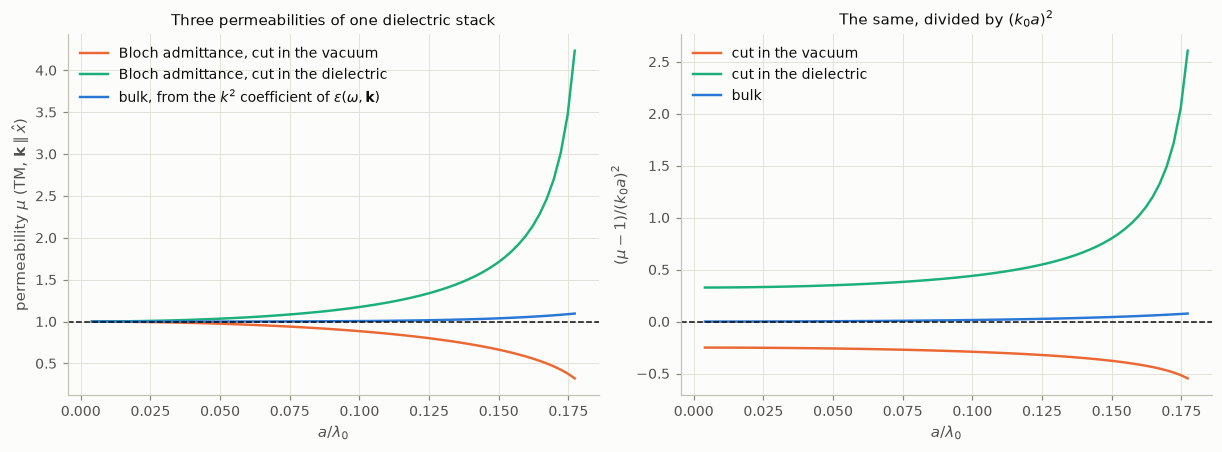

In [12]:
g_edge = lambda f: 0.5 * np.trace(lay.cell_transfer(TWO_PI * f, 0.0, STACK, "TM")).real
fgrid = np.linspace(0.01, 0.4, 400)
i_e = np.argmax(np.abs([g_edge(f) for f in fgrid]) > 1)
F_EDGE = brentq(lambda f: g_edge(f) + 1, fgrid[i_e - 1], fgrid[i_e])
print(f"first band edge at normal incidence: a/lambda = {F_EDGE:.5f}")
FB = np.linspace(0.004, 0.97 * F_EDGE, 70)
mu_bulk = np.array([1 / (1 - (TWO_PI * f) ** 2 * lay.tm_second_order(TWO_PI * f, STACK, 0.3)["cx"].real) for f in FB])
mu_cut = {}
for name, idx in (("vacuum", 1), ("dielectric", 0)):                              # layer that is cut in half
    res = [lay.bloch_admittance(TWO_PI * f, 0.0, STACK, "TM", idx) for f in FB]
    n_B = np.array([r[1].real for r in res]) / (TWO_PI * FB)
    Y_B = np.array([r[0] for r in res])
    assert np.abs(Y_B.imag).max() < 1e-9
    mu_cut[name] = n_B / Y_B.real

# the same two permeabilities from the explicit matrices of notebook 01, section 5.2
def layer_matrix(k0, d, eps):
    n = np.sqrt(complex(eps)); ph = n * k0 * d
    return np.array([[np.cos(ph), -1j * np.sin(ph) / n], [-1j * n * np.sin(ph), np.cos(ph)]])
def cell_matrix(k0, cut, eps_a=12.0, d_a=0.3):
    if cut == "vacuum":
        return layer_matrix(k0, (1 - d_a) / 2, 1) @ layer_matrix(k0, d_a, eps_a) @ layer_matrix(k0, (1 - d_a) / 2, 1)
    return layer_matrix(k0, d_a / 2, eps_a) @ layer_matrix(k0, 1 - d_a, 1) @ layer_matrix(k0, d_a / 2, eps_a)
def mu_nb01(f, cut):
    k0 = TWO_PI * f
    (A, B), (C, D) = cell_matrix(k0, cut)
    Y = np.sqrt(C / B); Y = Y if Y.real > 0 else -Y
    return (np.arccos(A.real) / k0) / Y.real
check("mu from the cut in the vacuum, layered.py against notebook 01's matrices (max difference)", max(abs(mu_cut["vacuum"][i] - mu_nb01(f, "vacuum")) for i, f in enumerate(FB)), 1e-9)
check("mu from the cut in the dielectric, layered.py against notebook 01's matrices (max difference)", max(abs(mu_cut["dielectric"][i] - mu_nb01(f, "dielectric")) for i, f in enumerate(FB)), 1e-9)
print(f"(mu - 1)/(k0 a)^2 at f = {FB[0]:.3f}: cut in the vacuum {(mu_cut['vacuum'][0] - 1) / (TWO_PI * FB[0])**2:+.4f}, cut in the dielectric {(mu_cut['dielectric'][0] - 1) / (TWO_PI * FB[0])**2:+.4f}, "
      f"bulk expansion {(mu_bulk[0] - 1) / (TWO_PI * FB[0])**2:+.5f}")
print(f"mu at 97% of the band edge: bulk {mu_bulk[-1]:.4f}, cut in the vacuum {mu_cut['vacuum'][-1]:.4f}, cut in the dielectric {mu_cut['dielectric'][-1]:.4f}")
assert (mu_cut["vacuum"] < 1).all() and (mu_cut["dielectric"] > 1).all() and (mu_bulk > 1).all()

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(FB, mu_cut["vacuum"], color=CAT[1], label="Bloch admittance, cut in the vacuum")
axs[0].plot(FB, mu_cut["dielectric"], color=CAT[2], label="Bloch admittance, cut in the dielectric")
axs[0].plot(FB, mu_bulk, color=CAT[0], label=r"bulk, from the $k^2$ coefficient of $\varepsilon(\omega,\mathbf{k})$")
axs[0].axhline(1.0, color=INK, ls="--", lw=1)
axs[0].set(xlabel=r"$a/\lambda_0$", ylabel=r"permeability $\mu$ (TM, $\mathbf{k}\parallel\hat{x}$)", title="Three permeabilities of one dielectric stack"); axs[0].legend()
for key, col, lab in (("vacuum", CAT[1], "cut in the vacuum"), ("dielectric", CAT[2], "cut in the dielectric")):
    axs[1].plot(FB, (mu_cut[key] - 1) / (TWO_PI * FB) ** 2, color=col, label=lab)
axs[1].plot(FB, (mu_bulk - 1) / (TWO_PI * FB) ** 2, color=CAT[0], label="bulk")
axs[1].axhline(0.0, color=INK, ls="--", lw=1)
axs[1].set(xlabel=r"$a/\lambda_0$", ylabel=r"$(\mu-1)/(k_0a)^2$", title="The same, divided by $(k_0a)^2$"); axs[1].legend()
plt.show()

Over the whole first band the bulk permeability stays above one and within about 10% of it (the printed value at 97% of the band edge), while the two Bloch permeabilities split to either side of one, with $(\mu-1)/(k_0a)^2$ of order one against a bulk value that is smaller by orders of magnitude at low frequency (right panel: the bulk curve is the flat line near zero). The index is one curve; the three permeabilities have three different low-frequency behaviors, $\propto f^4$ for the bulk and $\propto f^2$ with opposite signs for the two cuts. This is the stack version of the three-way disagreement found for TM rods in notebook 04. What differs between the three is not a magnetic response, since the layers have none.

## 3. The Bloch admittance against the bulk admittance, in closed form

At normal incidence the bulk admittance of a nonmagnetic description with the Bloch index is $y_{\rm bulk}=n_B$, and $Y_B/y_{\rm bulk}=1/\mu_B$. For the cell cut in the middle of the vacuum layer (the $T$ section of notebook 01) and in the middle of the dielectric layer (the $\Pi$ section), the series of the exact Bloch admittance in $k_0$ was computed with `sympy` outside this notebook:

$$\frac{Y_B}{n_B}-1=c\,(qa)^2+O\big((qa)^4\big),\qquad c_{\rm vac}=\frac{(1-\eta^2)}{12}\,\frac{s}{1+s},\qquad c_{\rm diel}=-\frac{(1-\eta)(2-\eta)}{12}\,\frac{s}{1+s},\qquad s=\eta(\varepsilon-1),$$

for a layer of permittivity $\varepsilon$ and thickness fraction $\eta$ in vacuum. The cell below recovers $c$ from `layered.bloch_admittance` at low frequency by a two-point extrapolation in $(qa)^2$ and compares.

In [13]:
def c_formula(eta, eps, cut):
    s = eta * (eps - 1)
    return (1 - eta ** 2) / 12 * s / (1 + s) if cut == "vacuum" else -(1 - eta) * (2 - eta) / 12 * s / (1 + s)

def c_numeric(eta, eps, cut, f1=1e-3):
    """(Y_B/n_B - 1)/(qa)^2 at two low frequencies, extrapolated linearly in (qa)^2 to zero."""
    layers, idx = [(eta, eps), (1 - eta, 1.0)], (1 if cut == "vacuum" else 0)
    pts = []
    for f in (f1, 2 * f1):
        Y, kxa = lay.bloch_admittance(TWO_PI * f, 0.0, layers, "TM", idx)
        pts.append((kxa.real ** 2, (Y.real / (kxa.real / (TWO_PI * f)) - 1) / kxa.real ** 2))
    (x1, y1), (x2, y2) = pts
    return y1 - x1 * (y2 - y1) / (x2 - x1)

print("   eta    eps      s     cut          c (exact, low-frequency limit)   c (closed form)")
rows = [(ETA, EPS_R), (0.5, 5.0), (0.1, 34.0), (0.05, 100.0), (0.05, 1000.0)]
for eta, eps in rows:
    for cut in ("vacuum", "dielectric"):
        cn, cf = c_numeric(eta, eps, cut, 1e-3 / np.sqrt(1 + eta * (eps - 1))), c_formula(eta, eps, cut)
        print(f"{eta:6.3f} {eps:7.1f} {eta * (eps - 1):7.2f}   {cut:10s} {cn:+22.6f} {cf:+22.6f}")
        check(f"coefficient c, eta = {eta}, eps = {eps}, cut in the {cut}: exact against closed form", cn - cf, 2e-5)
c_v, c_d = c_formula(ETA, EPS_R, "vacuum"), c_formula(ETA, EPS_R, "dielectric")
print(f"\nthis stack: c = {c_v:+.5f} (cut in the vacuum), {c_d:+.5f} (cut in the dielectric); (mu - 1)/(k0 a)^2 = -c <eps> = {-c_v * EPS_PAR:+.4f}, {-c_d * EPS_PAR:+.4f}")
check("(mu - 1)/(k0 a)^2 for the cut in the vacuum reproduces notebook 01's -0.25 to two decimals", -c_v * EPS_PAR, 0.005, -0.25)
check("(mu - 1)/(k0 a)^2 for the cut in the dielectric reproduces notebook 01's +0.33 to two decimals", -c_d * EPS_PAR, 0.005, 0.33)

   eta    eps      s     cut          c (exact, low-frequency limit)   c (closed form)
 0.300    12.0    3.30   vacuum                  +0.058198              +0.058198
PASS  coefficient c, eta = 0.3, eps = 12.0, cut in the vacuum: exact against closed form: got -1.77948e-13, target 0, |diff| 1.78e-13 <= 2e-05
 0.300    12.0    3.30   dielectric              -0.076105              -0.076105
PASS  coefficient c, eta = 0.3, eps = 12.0, cut in the dielectric: exact against closed form: got -8.24021e-13, target 0, |diff| 8.24e-13 <= 2e-05
 0.500     5.0    2.00   vacuum                  +0.041667              +0.041667
PASS  coefficient c, eta = 0.5, eps = 5.0, cut in the vacuum: exact against closed form: got 8.81774e-13, target 0, |diff| 8.82e-13 <= 2e-05
 0.500     5.0    2.00   dielectric              -0.041667              -0.041667
PASS  coefficient c, eta = 0.5, eps = 5.0, cut in the dielectric: exact against closed form: got 1.87942e-12, target 0, |diff| 1.88e-12 <= 2e-05
 0.100   

**The lumped limit.** In a ladder of lumped elements, a series inductance $L$ per cell and a shunt capacitance $C$, the $T$ section (half of $L$ on each side of $C$) has the Bloch relation $\sin(qa/2)=\omega\sqrt{LC}/2$ and the image admittance $Y_T=Y_0/\cos(qa/2)$ with $Y_0=\sqrt{C/L}$, and the $\Pi$ section has $Y_\Pi=Y_0\cos(qa/2)$. Those are the curves $1/\cos(qa/2)$ and $\cos(qa/2)$ of notebook 04, which are therefore ratios to the *static* admittance $Y_0$ of the line. The bulk admittance used for the rod lattice, and above, is $n_B=qa/k_0a$, which carries the dispersion of the Bloch wave as well: $n_B=Y_0\,(qa/2)/\sin(qa/2)$. Relative to $n_B$ the lumped $T$ and $\Pi$ ratios are

$$\frac{Y_T}{n_B}=\frac{\tan(qa/2)}{qa/2}=1+\frac{(qa)^2}{12}+\dots,\qquad\frac{Y_\Pi}{n_B}=\frac{\sin qa}{qa}=1-\frac{(qa)^2}{6}+\dots,$$

so the lumped limits of the coefficient are $+1/12$ and $-1/6$, not $\pm1/8$. The next cell checks this with the transfer matrices of an actual lumped ladder (no formula used), and compares with the stack.

PASS  lumped T section: Y_B/n_B from the ladder's transfer matrix against the closed form (max difference): got 0, target 0, |diff| 0.00e+00 <= 1e-10
lumped T section: (Y_B/n_B - 1)/(qa)^2 = +0.08335 at qa = 0.05
PASS  lumped T section: the coefficient tends to 1/12: got 0.0833542, target 0.0833333, |diff| 2.08e-05 <= 2e-03
PASS  lumped Pi section: Y_B/n_B from the ladder's transfer matrix against the closed form (max difference): got 1.11022e-16, target 0, |diff| 1.11e-16 <= 1e-10
lumped Pi section: (Y_B/n_B - 1)/(qa)^2 = -0.16665 at qa = 0.05
PASS  lumped Pi section: the coefficient tends to -1/6: got -0.166646, target -0.166667, |diff| 2.08e-05 <= 2e-03
stack, thin layer of large permittivity (s = eta (eps - 1) large):
  eta =  0.050, eps =     1000: c_vac = +0.08149, c_diel = -0.15135
  eta =  0.010, eps =    10000: c_vac = +0.08250, c_diel = -0.16255
  eta =  0.002, eps =   100000: c_vac = +0.08292, c_diel = -0.16534
PASS  thin high-index stack, cut in the vacuum: c tends to the l

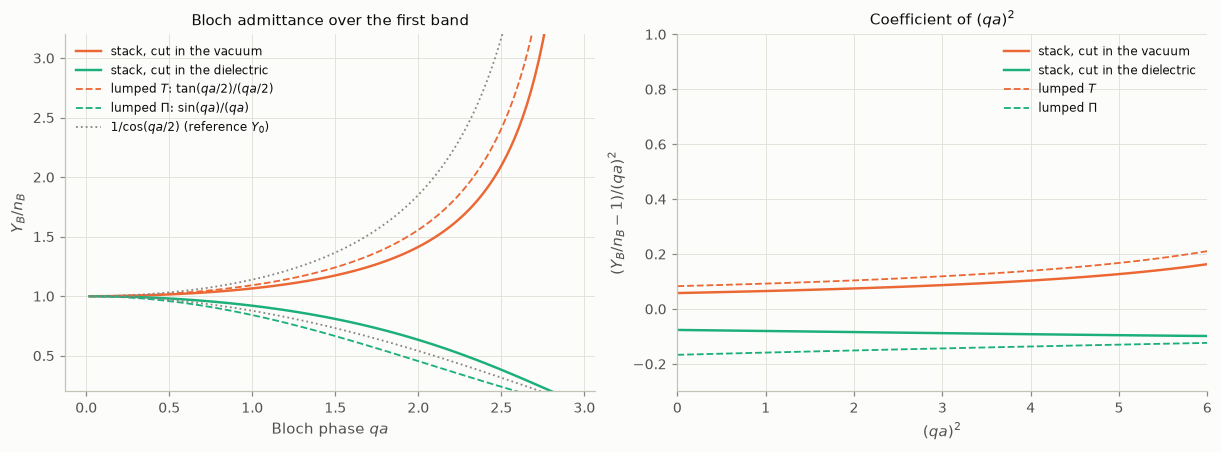

coefficient c (cut between the polarizable elements): lumped limit 0.0833; this stack 0.0582 = 0.70 of it; rod lattice of notebook 04 0.046 = 0.55 of it
notebook 04 compares with 1/8 = 0.125: ratio 2.7; against 1/12 the ratio is 1.8
factors of the stack coefficient: finite thickness 1 - eta^2 = 0.910, background capacitance s/(1 + s) = 0.767


In [14]:
def lumped_ratio_exact(qa, section):
    # n_B = qa / omega with omega = 1; static line admittance Y0 = sqrt(C/L)
    w = 2 * np.sin(qa / 2)
    Zs, Ys = -1j * 1.0, -1j * w ** 2
    S = lambda Z: np.array([[1, Z], [0, 1]], complex)
    P = lambda Y: np.array([[1, 0], [Y, 1]], complex)
    M = S(Zs / 2) @ P(Ys) @ S(Zs / 2) if section == "T" else P(Ys / 2) @ S(Zs) @ P(Ys / 2)
    q = np.arccos(M[0, 0].real)
    Y = (np.exp(1j * q) - M[0, 0]) / M[0, 1]
    Y = Y if Y.real > 0 else -Y
    return Y.real / (q / 1.0), q

qa_list = np.array([0.05, 0.1, 0.2])
for sec, formula in (("T", lambda x: np.tan(x / 2) / (x / 2)), ("Pi", lambda x: np.sin(x) / x)):
    got = np.array([lumped_ratio_exact(x, sec)[0] for x in qa_list])
    assert np.allclose([lumped_ratio_exact(x, sec)[1] for x in qa_list], qa_list)
    check(f"lumped {sec} section: Y_B/n_B from the ladder's transfer matrix against the closed form (max difference)", np.abs(got - formula(qa_list)).max(), 1e-10)
    c_lump = (got[0] - 1) / qa_list[0] ** 2
    print(f"lumped {sec} section: (Y_B/n_B - 1)/(qa)^2 = {c_lump:+.5f} at qa = {qa_list[0]}")
    check(f"lumped {sec} section: the coefficient tends to {'1/12' if sec == 'T' else '-1/6'}", c_lump, 2e-3, 1 / 12 if sec == "T" else -1 / 6)
# the thin, high-index limit of the stack is the lumped ladder
print("stack, thin layer of large permittivity (s = eta (eps - 1) large):")
for eta, eps in [(0.05, 1000.0), (0.01, 10000.0), (0.002, 100000.0)]:
    print(f"  eta = {eta:6.3f}, eps = {eps:8.0f}: c_vac = {c_numeric(eta, eps, 'vacuum', 1e-3 / np.sqrt(1 + eta * (eps - 1))):+.5f}, c_diel = {c_numeric(eta, eps, 'dielectric', 1e-3 / np.sqrt(1 + eta * (eps - 1))):+.5f}")
c_thin = (c_numeric(0.002, 1e5, "vacuum", 1e-3 / np.sqrt(1 + 0.002 * (1e5 - 1))), c_numeric(0.002, 1e5, "dielectric", 1e-3 / np.sqrt(1 + 0.002 * (1e5 - 1))))
check("thin high-index stack, cut in the vacuum: c tends to the lumped T value 1/12", c_thin[0], 5e-3, 1 / 12)
check("thin high-index stack, cut in the dielectric: c tends to the lumped Pi value -1/6", c_thin[1], 1.5e-2, -1 / 6)

# figure: the ratio Y_B/n_B over the first band against the lumped curves
QA = np.linspace(0.02, 0.93 * np.pi, 120)
curves = {}
for name, idx in (("vacuum", 1), ("dielectric", 0)):
    fq = []
    for qa in QA:                                                                 # find the frequency with Bloch phase qa
        fq.append(brentq(lambda f: lay.bloch_kx(TWO_PI * f, 0.0, STACK, "TM").real - qa, 1e-4, F_EDGE * 0.9999))
    fq = np.array(fq)
    Y = np.array([lay.bloch_admittance(TWO_PI * f, 0.0, STACK, "TM", idx)[0].real for f in fq])
    curves[name] = Y / (QA / (TWO_PI * fq))
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ax = axs[0]
ax.plot(QA, curves["vacuum"], color=CAT[1], label="stack, cut in the vacuum")
ax.plot(QA, curves["dielectric"], color=CAT[2], label="stack, cut in the dielectric")
ax.plot(QA, np.tan(QA / 2) / (QA / 2), color=CAT[1], ls="--", lw=1.2, label=r"lumped $T$: $\tan(qa/2)/(qa/2)$")
ax.plot(QA, np.sin(QA) / QA, color=CAT[2], ls="--", lw=1.2, label=r"lumped $\Pi$: $\sin(qa)/(qa)$")
ax.plot(QA, 1 / np.cos(QA / 2), color=MUTED, ls=":", lw=1.2, label=r"$1/\cos(qa/2)$ (reference $Y_0$)")
ax.plot(QA, np.cos(QA / 2), color=MUTED, ls=":", lw=1.2)
ax.set_ylim(0.2, 3.2)
ax.set(xlabel=r"Bloch phase $qa$", ylabel=r"$Y_B/n_B$", title="Bloch admittance over the first band"); ax.legend(fontsize=8)
ax = axs[1]
for name, col in (("vacuum", CAT[1]), ("dielectric", CAT[2])):
    ax.plot(QA ** 2, (curves[name] - 1) / QA ** 2, color=col, label=f"stack, cut in the {name}")
ax.plot(QA ** 2, (np.tan(QA / 2) / (QA / 2) - 1) / QA ** 2, color=CAT[1], ls="--", lw=1.2, label="lumped $T$")
ax.plot(QA ** 2, (np.sin(QA) / QA - 1) / QA ** 2, color=CAT[2], ls="--", lw=1.2, label=r"lumped $\Pi$")
ax.set(xlabel=r"$(qa)^2$", ylabel=r"$(Y_B/n_B-1)/(qa)^2$", title="Coefficient of $(qa)^2$", xlim=(0, 6), ylim=(-0.3, 1.0)); ax.legend(fontsize=8)
assert ((curves["vacuum"] > 1) & (curves["vacuum"] < np.tan(QA / 2) / (QA / 2))).all(), "cut in the vacuum: between one and the lumped T curve"
assert ((curves["dielectric"] < 1) & (curves["dielectric"] > np.sin(QA) / QA)).all(), "cut in the dielectric: between the lumped Pi curve and one"
plt.show()

# the comparison with the rod lattice of notebook 04
C_ROD = 0.046                                  # coefficient quoted for the TM rod lattice in notebook 04 and the README
print(f"coefficient c (cut between the polarizable elements): lumped limit {1 / 12:.4f}; this stack {c_v:.4f} = {12 * c_v:.2f} of it; rod lattice of notebook 04 {C_ROD} = {12 * C_ROD:.2f} of it")
print(f"notebook 04 compares with 1/8 = {1 / 8}: ratio {1 / 8 / C_ROD:.1f}; against 1/12 the ratio is {1 / 12 / C_ROD:.1f}")
print(f"factors of the stack coefficient: finite thickness 1 - eta^2 = {1 - ETA ** 2:.3f}, background capacitance s/(1 + s) = {ETA * (EPS_R - 1) / (1 + ETA * (EPS_R - 1)):.3f}")

**Reading.** Three things in the printed tables.

- The exact coefficients of the stack are the closed forms above. For the cut in the vacuum, $c_{\rm vac}=\frac{1-\eta^2}{12}\frac{s}{1+s}$ is $1/12$ times two factors that are smaller than one: $1-\eta^2$, for a polarizable layer of finite thickness (the lumped limit has $\eta\to0$), and $s/(1+s)$, because the vacuum arms carry capacitance too, which the ladder leaves out. The thin high-index limit reproduces the lumped $T$ and $\Pi$ values, and the dielectric-cut coefficient has the corresponding factors $(1-\eta)(2-\eta)/2\to1$ and $s/(1+s)\to1$ with $-1/6$ in front. The printed lines give the numbers for this stack.
- The $\pm1/8$ of notebook 04 is the limit for the ratio to the static line admittance. Notebook 04's coefficient 0.046 uses the Bloch-index reference: $y_{\rm bulk}=n_{\rm bulk}/\mu_{\rm bulk}$ with $n_{\rm bulk}^2=\varepsilon_{\rm bulk}\mu_{\rm bulk}$, which agrees with the Bloch index to the order that matters here (notebook 04 now checks this). Against that reference the lumped limit is $1/12$. So the factor 2.7 that notebook 04 used to quote becomes the smaller factor printed above for a like-for-like comparison (notebook 04 now compares with $1/12$), and the stack, with extended polarizable layers, gets a larger fraction of the lumped value than the rod lattice does (both fractions are printed). This is a hypothesis for the rods, not a result: the rod lattice is two-dimensional and the analogy to a stack is the shape of the argument (an extended element between the cuts and background capacitance in the arms), not a computation.
- The curves in the figure: over the whole first band the stack's ratio lies between one and the lumped curve of the same cut (asserted in the cell), and both diverge from one more slowly than the lumped curves do.

## 4. A metal-dielectric stack near epsilon-near-zero

The best-known strong nonlocality of a multilayer is not magnetic. Take a Drude metal, $\varepsilon_m=1-f_p^2/[f(f+if_\gamma)]$ with $f_p=a/\lambda_p$, in layers of thickness $0.25\,a$ alternating with a dielectric of permittivity 4 (thickness $0.75\,a$), with $f_p=0.25$ (a silver-like plasma frequency: $\lambda_p\approx140$ nm gives $a\approx35$ nm and metal layers of about 9 nm; the Drude model used here has no interband terms and a single small loss, so the stack is a model, not a silver design). The local effective-medium permittivities are

$$\varepsilon_\parallel=\langle\varepsilon\rangle=0.25\,\varepsilon_m+3,\qquad\varepsilon_\perp=\frac{1}{0.25/\varepsilon_m+0.75/4}.$$

$\varepsilon_\parallel$ crosses zero when $f_p^2/f^2=13$, at $f=f_p/\sqrt{13}$, well below $a/\lambda_0=0.1$. For TE (H along $z$) with $\mathbf E$ in the plane, the local dispersion relation is $k_x^2/\varepsilon_\parallel+k_y^2/\varepsilon_\perp=k_0^2$ ($\varepsilon_\parallel=\varepsilon_{yy}$, $\varepsilon_\perp=\varepsilon_{xx}$). Below the crossing $\varepsilon_\parallel<0<\varepsilon_\perp$ and the contour is a hyperbola, above it an ellipse; the cell below finds the exact ENZ frequency from the transfer matrix ($k_x=0$ at $k_y=0$) of this metal stack and compares it with the local one.

In [15]:
FP, DM, EPS_D = 0.25, 0.25, 4.0

def metal_stack(f, fg=0.0):
    em = 1 - FP ** 2 / (f * (f + 1j * fg))
    return [(DM, em), (1 - DM, EPS_D)]

F_LOCAL = FP / np.sqrt(1 + (1 - DM) * EPS_D / DM)
g_enz = lambda f: 0.5 * np.trace(lay.cell_transfer(TWO_PI * f, 0.0, metal_stack(f), "TE")).real - 1.0
F_EXACT = brentq(g_enz, 0.8 * F_LOCAL, 1.2 * F_LOCAL, xtol=1e-14)
print(f"ENZ of the local effective medium (<eps> = 0): a/lambda = {F_LOCAL:.5f}")
print(f"ENZ of the exact stack (k_x = 0 at k_y = 0)  : a/lambda = {F_EXACT:.5f}   (shift {100 * (F_EXACT / F_LOCAL - 1):+.2f} %)")
co_E = lay.te_second_order(TWO_PI * F_EXACT, metal_stack(F_EXACT), 0.5)
check("at the exact ENZ frequency eps_yy(w, k = 0) is zero (it is the Bloch condition at k_x = k_y = 0)", abs(co_E["e_yy"]), 1e-9)
co_Loc = lay.te_second_order(TWO_PI * F_LOCAL, metal_stack(F_LOCAL), 0.5)
rytov_shift = C_rytov(metal_stack(F_LOCAL)).real * (TWO_PI * F_LOCAL) ** 2
print(f"at the local ENZ frequency: eps_yy(w, 0) = {co_Loc['e_yy'].real:.5f}; the Rytov term C k0^2 with C = eta^2 (1 - eta)^2 (eps_m - eps_d)^2 / 12 is {rytov_shift:.5f}")
check("the shift of eps_yy(w, 0) away from <eps> at the local ENZ is the Rytov term (relative difference)", co_Loc["e_yy"].real / rytov_shift - 1, 0.05)
for f in (0.8 * F_EXACT, 0.95 * F_EXACT, F_EXACT, 1.05 * F_EXACT, 1.2 * F_EXACT):
    ly = metal_stack(f); ep, eperp = [v.real for v in lay.local_eps(ly)]
    print(f"   f = {f:.4f} ({f / F_EXACT:.2f} f_ENZ): local eps_par = {ep:+.4f}, eps_perp = {eperp:.4f}")

ENZ of the local effective medium (<eps> = 0): a/lambda = 0.06934
ENZ of the exact stack (k_x = 0 at k_y = 0)  : a/lambda = 0.06786   (shift -2.14 %)
PASS  at the exact ENZ frequency eps_yy(w, k = 0) is zero (it is the Bloch condition at k_x = k_y = 0): got 1.05496e-15, target 0, |diff| 1.05e-15 <= 1e-09
at the local ENZ frequency: eps_yy(w, 0) = 0.13970; the Rytov term C k0^2 with C = eta^2 (1 - eta)^2 (eps_m - eps_d)^2 / 12 is 0.14235
PASS  the shift of eps_yy(w, 0) away from <eps> at the local ENZ is the Rytov term (relative difference): got -0.0185938, target 0, |diff| 1.86e-02 <= 5e-02
   f = 0.0543 (0.80 f_ENZ): local eps_par = -2.0524, eps_perp = 5.7101
   f = 0.0645 (0.95 f_ENZ): local eps_par = -0.5101, eps_perp = 5.8929
   f = 0.0679 (1.00 f_ENZ): local eps_par = -0.1435, eps_perp = 5.9660
   f = 0.0712 (1.05 f_ENZ): local eps_par = +0.1720, eps_perp = 6.0460
   f = 0.0814 (1.20 f_ENZ): local eps_par = +0.8934, eps_perp = 6.3359


The exact ENZ frequency is lower than the local one: at the local crossing, $\varepsilon_{yy}(\omega,\mathbf k=0)$ is positive (printed), and the printed comparison shows that it equals the Rytov term of section 2.2 to within the stated tolerance (the contrast $\varepsilon_m-\varepsilon_d\approx-16$ at the crossing is large). That is frequency dispersion at $k=0$ and has nothing to do with a wavevector: $\mathbf E$ is tangential, and the second-order correction is $C\,k_0^2$ with $C=\eta^2(1-\eta)^2(\varepsilon_m-\varepsilon_d)^2/12$. The next cells compare three descriptions of the contours with the exact Bloch condition: (i) the static local medium, (ii) a local medium whose $\varepsilon_{xx}$ and $\varepsilon_{yy}$ are the exact $\varepsilon(\omega,\mathbf k=0)$ at the frequency (this includes all of the frequency dispersion and none of the $k$ dependence), and (iii) the second-order tensor of section 2.3 (those two plus the five $k^2$ coefficients $A,\dots,E$ at the frequency). The roots of the second-order dispersion determinant, $\det[k_0^2\varepsilon(\omega,\mathbf k)-(k^2I-\mathbf k\mathbf k^{\mathsf T})]=0$, are solved for $k_x^2$ at each $k_y$ (it is polynomial in $k_x^2$).

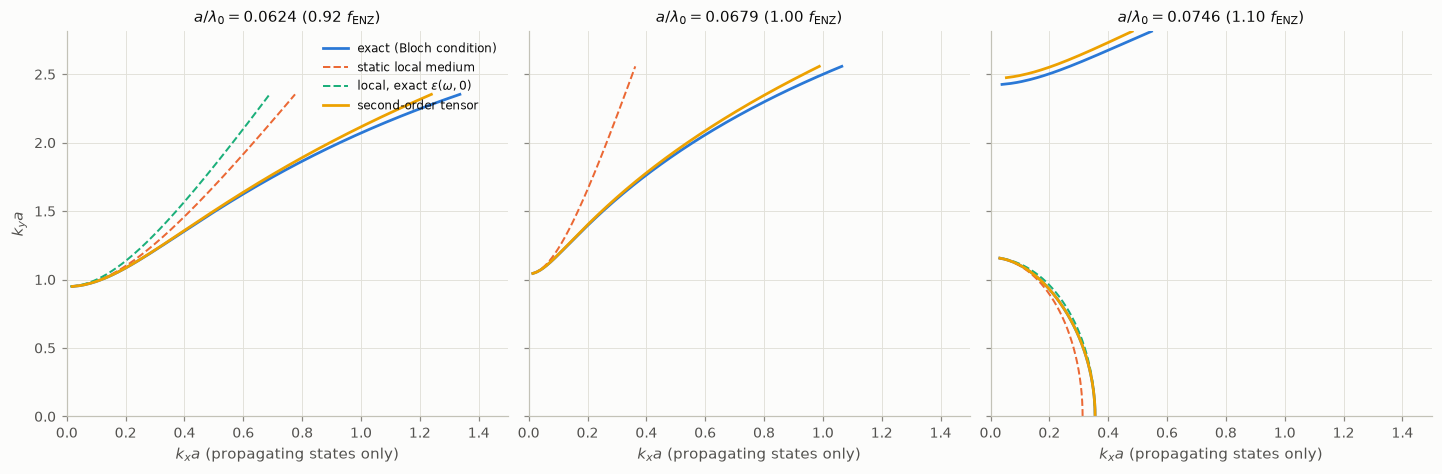

In [16]:
def models(f, ky, fg=0.0, co=None):
    """k_x of the exact Bloch wave and of the three models, all on the branch that propagates or decays toward +x."""
    ly = metal_stack(f, fg); k0 = TWO_PI * f
    if co is None:
        co = lay.te_second_order(k0, ly, 0.5)
    ep, eperp = lay.local_eps(ly)
    ex = canon(lay.bloch_kx(k0, ky, ly, "TE"))
    loc = canon(np.sqrt(ep * (k0 ** 2 - ky ** 2 / eperp)))
    loc0 = canon(np.sqrt(co["e_yy"] * (k0 ** 2 - ky ** 2 / co["e_xx"])))
    roots = lay.te_model_kx(k0, ky, co)
    sec = canon(np.sqrt(roots[0] + 0j))
    return ex, loc, loc0, sec

def fail_point(f, fg=0.0, thresh=0.05, co=None, kmax=6.0, n=241):
    """Smallest k_y / k0 at which each model's k_x differs from the exact one by more than `thresh`, relative to max(|k_x|, 0.1 k0)
    (the floor keeps the measure finite at the ENZ point, where the exact k_x is zero); 0 if already at k_y = 0."""
    k0 = TWO_PI * f
    kys = np.linspace(0, kmax * k0, n)
    err = np.array([[abs(m - e) / max(abs(e), 0.1 * k0) for m in mm[1:]] for e, mm in ((r[0], r) for r in (models(f, ky, fg, co) for ky in kys))])
    out = []
    for j in range(3):
        bad = np.where(err[:, j] > thresh)[0]
        out.append(kys[bad[0]] / k0 if len(bad) else np.inf)
    return out, err[0], kys / k0, err

FS_C = [F_EXACT * 0.92, F_EXACT, F_EXACT * 1.1]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, f in zip(axs, FS_C):
    k0 = TWO_PI * f
    kys = np.linspace(0, 6 * k0, 400)
    co = lay.te_second_order(k0, metal_stack(f), 0.5)
    mm = np.array([models(f, ky, 0.0, co) for ky in kys])
    for j, (lab, col, ls) in enumerate((("exact (Bloch condition)", CAT[0], "-"), ("static local medium", CAT[1], "--"),
                                         (r"local, exact $\varepsilon(\omega,0)$", CAT[2], "--"), ("second-order tensor", CAT[3], "-"))):
        kx = mm[:, j]
        prop = np.abs(kx.imag) < 1e-9
        ax.plot(np.where(prop, kx.real, np.nan), kys, color=col, ls=ls, lw=1.8 if j in (0, 3) else 1.3, label=lab)
    ax.set(xlabel=r"$k_x a$ (propagating states only)", title=rf"$a/\lambda_0={f:.4f}$ ({f / F_EXACT:.2f} $f_{{\rm ENZ}}$)", xlim=(0, 1.5), ylim=(0, 6 * k0))
axs[0].set_ylabel(r"$k_y a$"); axs[0].legend(fontsize=8, loc="upper right")
plt.show()

Left and middle panels: below and at the ENZ frequency the exact contour is a hyperbola-like branch that starts at a finite $k_y$ and rises; the static local medium (dashed) has the same cutoff (the vertex $k_y=\sqrt{\varepsilon_{xx}}\,k_0$) but a different slope; in the left panel the local medium with the exact $\varepsilon(\omega,0)$ follows the exact curve near the cutoff and then departs as $k_y$ grows (at $f_{\rm ENZ}$ it is degenerate, $\varepsilon_{yy}=0$, and is not drawn in the middle panel), and the second-order tensor follows the exact curve much further. Right panel, above the crossing: the small elliptical piece and, beyond a gap in $k_y$ where $k_x$ is imaginary, a second propagating branch at large $k_y$ that the local models do not have at all. The second-order tensor has it. The next cell puts numbers on this.

   f / f_ENZ   error of k_x at k_y = 0 (static local, local with eps(w,0), 2nd order)    k_y/k0 where k_x is off by 5% (same three)
    0.850          0.067    0.0008   5.3e-06                0.00   1.93   5.50
    0.875          0.081    0.0008   4.6e-06                0.00   1.77   5.52
    0.900          0.100    0.0008   3.8e-06                0.00   1.62   5.52
    0.925          0.133    0.0008   3.0e-06                0.00   1.42   5.52
    0.950          0.195    0.0009   2.1e-06                0.00   1.18   5.53
    0.975          0.364    0.0009   1.1e-06                0.00   0.85   5.48
    1.000          3.788    0.0000   0.0e+00                0.00   0.05   5.42
    1.025          0.646    0.0009   1.1e-06                0.00   0.82   2.60
    1.050          0.252    0.0009   2.4e-06                0.00   1.20   3.40
    1.075          0.161    0.0010   3.7e-06                0.00   1.50   4.07
    1.100          0.120    0.0010   5.1e-06                0.00   1.78   4.65

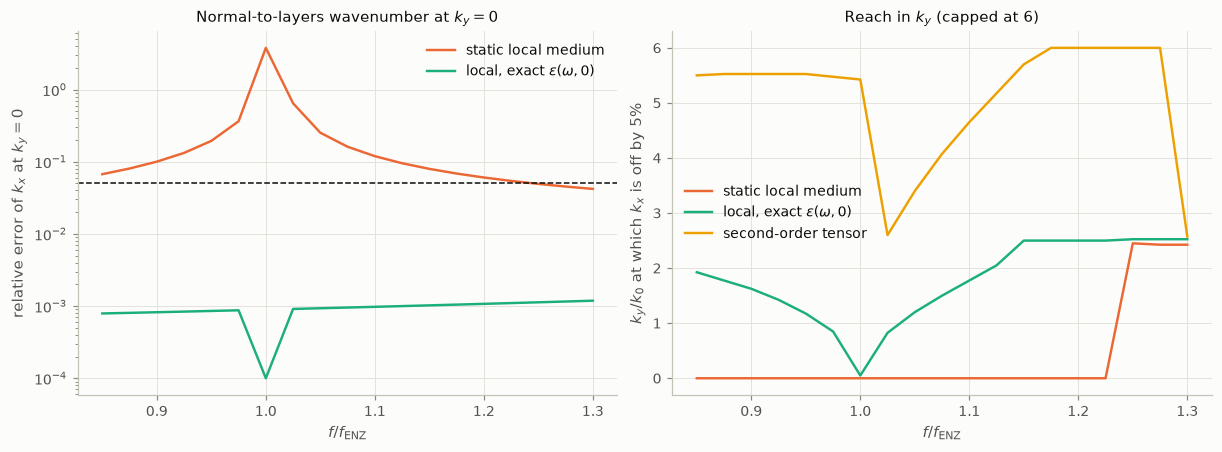

In [17]:
FSWEEP = F_EXACT * np.linspace(0.85, 1.3, 19)    # includes f_ENZ itself
fails, err0 = [], []
for f in FSWEEP:
    fp_, e0, _, _ = fail_point(f)
    fails.append(fp_); err0.append(e0)
fails, err0 = np.array(fails), np.array(err0)
print("   f / f_ENZ   error of k_x at k_y = 0 (static local, local with eps(w,0), 2nd order)    k_y/k0 where k_x is off by 5% (same three)")
for r, f, e0, fl in zip(range(len(FSWEEP)), FSWEEP, err0, fails):
    print(f"   {f / F_EXACT:6.3f}      {e0[0]:9.3f} {e0[1]:9.4f} {e0[2]:9.1e}              {fl[0]:6.2f} {fl[1]:6.2f} {fl[2]:6.2f}")
i1 = np.argmin(np.abs(FSWEEP - F_EXACT))
sel = FSWEEP <= 1.1 * F_EXACT * (1 + 1e-9)
ratio_reach = fails[sel, 2] / fails[sel, 1]
ratio_reach = ratio_reach[np.isfinite(ratio_reach)]
print(f"reach of the second-order tensor / reach of the local model with eps(w,0), for f <= 1.1 f_ENZ: smallest {ratio_reach.min():.1f}; hyperbola vertex sqrt(eps_xx) = {np.sqrt(lay.local_eps(metal_stack(F_EXACT))[1].real):.2f} k0 at f_ENZ")
print("reach of the same two models for f > 1.1 f_ENZ (inf: no failure within k_y = 6 k0):", [(round(float(f / F_EXACT), 3), round(float(a), 2), round(float(b), 2)) for f, a, b in zip(FSWEEP[~sel], fails[~sel, 1], fails[~sel, 2])])
(fp_E, e0_E, kys_E, err_E) = fail_point(F_EXACT)
print(f"\nat the exact ENZ frequency: static local medium error at k_y = 0 is {e0_E[0]:.2f} (relative), local with exact eps(w,0) fails (5%) at k_y = {fp_E[1]:.2f} k0 = {fp_E[1] * TWO_PI * F_EXACT:.3f}/a, "
      f"second-order tensor at k_y = {fp_E[2]:.2f} k0 = {fp_E[2] * TWO_PI * F_EXACT:.3f}/a")
assert (fails[:, 0] <= fails[:, 1] + 1e-9).all() and (fails[:, 1] <= fails[:, 2] + 1e-9).all(), "static local fails first, then local with eps(w, 0), then the second-order model"
check("the second-order tensor reproduces k_x at k_y = 0 at every frequency of the sweep (max relative error)", err0[:, 2].max(), 1e-3)
assert err0[:, 0].max() > 0.5, "the static local medium misses k_x at k_y = 0 by a large factor near the crossing"
print(f"largest relative error of the static local k_x at k_y = 0 in the sweep: {err0[:, 0].max():.2f}")
f_ok = FSWEEP[err0[:, 0] < 0.05][0] / F_EXACT
print(f"the static local k_x at k_y = 0 is within 5% only from f = {f_ok:.3f} f_ENZ up (in the sweep)")
f9 = 0.9 * F_EXACT
co9 = lay.te_second_order(TWO_PI * f9, metal_stack(f9), 0.5)
print(f"k_x against k_y at f = 0.9 f_ENZ (k0 = {TWO_PI * f9:.4f}): exact and second-order tensor")
for r_ in (3, 4, 5, 5.5, 6, 7):
    ex_, _, _, sec_ = models(f9, r_ * TWO_PI * f9, 0.0, co9)
    print(f"   k_y/k0 = {r_:3.1f} (k_y a = {r_ * TWO_PI * f9:.3f}): exact {ex_.real:.4f}, second order {sec_.real:.4f}, relative difference {abs(ex_ - sec_) / abs(ex_):.3f}")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].semilogy(FSWEEP / F_EXACT, np.maximum(err0[:, 0], 1e-4), color=CAT[1], label="static local medium")
axs[0].semilogy(FSWEEP / F_EXACT, np.maximum(err0[:, 1], 1e-4), color=CAT[2], label=r"local, exact $\varepsilon(\omega,0)$")
axs[0].axhline(0.05, color=INK, ls="--", lw=1)
axs[0].set(xlabel=r"$f/f_{\rm ENZ}$", ylabel=r"relative error of $k_x$ at $k_y=0$", title="Normal-to-layers wavenumber at $k_y=0$"); axs[0].legend()
for j, (lab, col) in enumerate((("static local medium", CAT[1]), (r"local, exact $\varepsilon(\omega,0)$", CAT[2]), ("second-order tensor", CAT[3]))):
    axs[1].plot(FSWEEP / F_EXACT, np.minimum(fails[:, j], 6.0), color=col, label=lab)
axs[1].set(xlabel=r"$f/f_{\rm ENZ}$", ylabel=r"$k_y/k_0$ at which $k_x$ is off by 5%", title="Reach in $k_y$ (capped at 6)"); axs[1].legend()
plt.show()

The printed table says where each description fails although $a/\lambda_0<0.1$ throughout. The static local medium has the wrong $k_x$ at $k_y=0$ (the error column; the shift of the ENZ frequency seen above) by more than 5% over most of the sweep, and by a factor of several at the crossing itself, where the exact $k_x$ is zero. The local medium that has the exact $\varepsilon(\omega,0)$ is right at $k_y=0$ and loses 5% at a $k_y$ between a few hundredths of $k_0$ (at the crossing, where $\varepsilon_{yy}\to0$ and the floor in the error measure matters) and a few times $k_0$ (the second column of the right-hand block). The second-order tensor reaches further at every frequency of the table; at the frequencies up to the crossing its error grows smoothly with $k_y$ (the second printout above) and it is 5% off at $k_y\approx2$ to $2.3/a$, to be compared with $1/a$, the scale of the layer thicknesses (the stack is uniform along $y$, so $k_y$ has no zone boundary). **Limits of this comparison.** The reach quoted is that of one local model, the one with $\varepsilon(\omega,0)$, not of locality in general. The reach quoted is against one local model only; a different local model was not computed in this notebook, so no factor against "locality in general" is claimed. The failures of the local models lie in the evanescent region below the hyperbola vertex $k_y=\sqrt{\varepsilon_{xx}}\,k_0$ (printed above) for $f\le f_{\rm ENZ}$, and above about $1.2\,f_{\rm ENZ}$ the reach is set by where the elliptical piece closes, where the relative-error measure is ill-conditioned, so "a few times" is claimed only for $f\lesssim1.1\,f_{\rm ENZ}$ (the printed ratio). That locality fails near ENZ is robust; the factor by which the second-order tensor extends the reach is not.

**The coefficients.** What are the second-order coefficients near the crossing, how large are they against the local terms, and which of them is magnetic by form? The table prints the five coefficients at a few frequencies around the exact ENZ, together with $k_*$, the value of $k$ in units of $k_0$ at which each second-order term equals the corresponding local term (the smaller $k_*$, the sooner the term matters), and the magnetic projection of section 2.3.

In [18]:
FCO = F_EXACT * np.array([0.9, 0.95, 1.0, 1.05, 1.1, 1.2])
print("   f/f_ENZ   e_xx       e_yy        A          B          C          D          E     |  chi/k0^2  share  | avg metric: chi/k0^2  share |  k*_B   k*_C   k*_D   (units of k0)")
co_tab, shares_m = [], []
co_r1, co_r2 = lay.te_second_order(TWO_PI * F_EXACT, metal_stack(F_EXACT), 0.1 * TWO_PI * F_EXACT), lay.te_second_order(TWO_PI * F_EXACT, metal_stack(F_EXACT), 1.0)
check("the metal-stack coefficients do not depend on the Cauchy radius (C, D and E at the ENZ frequency, circle of 0.1 k0 against 1/a; max relative difference)", max(abs(co_r1[k] / co_r2[k] - 1) for k in ("C", "D", "E")), 1e-7)
for f in FCO:
    k0 = TWO_PI * f
    co = lay.te_second_order(k0, metal_stack(f), 0.5)
    co_tab.append(co)
    v, chi, share = te_split(co, k0)
    chi_a, share_a = te_split_avg(co)
    shares_m += [share, share_a]
    kB = np.sqrt(abs(co["e_xx"] / co["B"])) / k0
    kC = np.sqrt(abs(co["e_yy"] / co["C"])) / k0
    kD = np.sqrt(abs(co["e_yy"] / co["D"])) / k0
    print(f"   {f / F_EXACT:6.3f} {co['e_xx'].real:8.4f} {co['e_yy'].real:+10.5f} {co['A'].real:+9.1e} {co['B'].real:+10.5f} {co['C'].real:+10.5f} {co['D'].real:+10.5f} {co['E'].real:+10.5f}  | {chi:+10.5f} {share:7.3f} | {chi_a:+10.5f} {share_a:7.3f}     | {kB:6.2f} {kC:6.2f} {kD:6.2f}")
    assert co["resid"] < 1e-8
assert min(shares_m) > 0.8, "the non-magnetic share stays large in both metrics"
print(f"smallest non-magnetic share in this table, over both metrics: {min(shares_m):.3f}")
check("A = 0 also for the metal stack (max |A| over the table)", max(abs(c["A"]) for c in co_tab), 1e-9)
check("e_xx equals 1/<1/eps> for the metal stack at the exact ENZ frequency (relative)", co_tab[2]["e_xx"].real / lay.local_eps(metal_stack(FCO[2]))[1].real - 1, 1e-9)
co0 = lay.te_second_order(TWO_PI * 1e-4, [(DM, -10.0), (1 - DM, EPS_D)], 0.3)
print(f"\nstatic limit at fixed eps_m = -10 (f = 1e-4): B = {co0['B'].real:+.6f}, closed form {B0_formula([(DM, -10.0), (1 - DM, EPS_D)]):+.6f}")

   f/f_ENZ   e_xx       e_yy        A          B          C          D          E     |  chi/k0^2  share  | avg metric: chi/k0^2  share |  k*_B   k*_C   k*_D   (units of k0)
PASS  the metal-stack coefficients do not depend on the Cauchy radius (C, D and E at the ENZ frequency, circle of 0.1 k0 against 1/a; max relative difference): got 1.20487e-11, target 0, |diff| 1.20e-11 <= 1e-07
    0.900   5.8263   -0.77463  -1.1e-15   -0.00891   +0.01121   -0.18921   -0.10382  |   +0.03537   0.959 |   +0.00317   1.000     |  66.66  21.66   5.27
    0.950   5.8929   -0.35682  -2.0e-15   -0.00507   +0.01046   -0.15635   -0.09861  |   +0.03467   0.946 |   +0.00713   0.998     |  84.21  14.42   3.73
    1.000   5.9660   +0.00000  -8.9e-16   -0.00131   +0.00982   -0.13070   -0.09444  |   +0.03432   0.930 |   +0.01047   0.993     | 158.51   0.00   0.00
    1.050   6.0460   +0.30717  -8.9e-16   +0.00247   +0.00929   -0.11039   -0.09117  |   +0.03431   0.910 |   +0.01340   0.986     | 110.47  12.85   3.7

Reading the table:

- **Size.** $B$ and $C$ are of order $10^{-2}a^2$ or smaller, $D$ and $E$ of order $10^{-1}a^2$, and $D$ (longitudinal along the layers) is the largest up to $1.1\,f_{\rm ENZ}$ (at $1.2\,f_{\rm ENZ}$ the printed $E$ is larger in magnitude). Against $\varepsilon_{xx}\approx6$ they are small: $k_*$ for $B$ is $40$ to $160\,k_0$ and for $C$ it is $13$ to $22\,k_0$ away from the crossing. For $C$ (a $k_x^2$ coefficient) this is outside the Brillouin zone $|k_x|<\pi/a$; for $B$ (a $k_y^2$ coefficient) there is no zone along $y$, and the comparison is with $1/a$, the scale of the layer thicknesses. For $\varepsilon_{yy}$ the $D$ term catches up with the local value at $k_*$ of a few $k_0$ away from the crossing, and $k_*\to0$ at the crossing for both $C$ and $D$ (the last columns), since $\varepsilon_{yy}$ crosses zero: right at ENZ any nonzero $k^2$ coefficient decides what the medium does.
- **Which one is magnetic.** A $\mu_{zz}$ would make $A=D=0$ and $B=C=-E$. Of these $A=0$ holds exactly (section 2.3), but the table has $D$ of order $10^{-1}$ and $E$ of order $10^{-1}$ against $B$ and $C$ of order $10^{-2}$, with $B$ changing sign across the range. So the pattern of a permeability is far from what the stack has; the part of the vector along the magnetic direction (the projections of section 2.3, two conventions, printed as $\chi/k_0^2$ together with the share of the vector that is left over) is the smaller part of the vector (the printed non-magnetic share is at least 0.83 in both metrics), its value depends on the convention (compare the two printed $\chi/k_0^2$ columns), and it does not stand for a separate physical response. What matters near the crossing is the longitudinal coefficient $D$, which no $\mu_{zz}$ can produce.

### 4.1 A small loss

With a loss $f_\gamma=0.002$ ($f_\gamma/f_p=0.8\%$) the metal permittivity gets an imaginary part, $\varepsilon_{yy}(\omega,0)$ no longer vanishes at the lossless ENZ frequency, and the contours are lines in the complex $k_x$ plane. The cell below repeats the comparison of the contour at the exact lossless ENZ frequency with the loss on.

In [19]:
FG = 0.002
ly_loss = metal_stack(F_EXACT, FG)
co_L = lay.te_second_order(TWO_PI * F_EXACT, ly_loss, 0.5)
scale = max(abs(co_E[k]) for k in ("B", "C", "D", "E"))
dco = {k: abs(co_L[k] - co_E[k]) / scale for k in ("B", "C", "D", "E")}
print(f"with f_gamma = {FG}: eps_yy(w, 0) = {co_L['e_yy']:.5f} (lossless: {co_E['e_yy'].real:.1e})")
print("coefficient   lossless      with loss                 change / largest lossless coefficient")
for k in ("B", "C", "D", "E"):
    print(f"   {k}        {co_E[k].real:+.5f}   {co_L[k].real:+.5f} {co_L[k].imag:+.5f}i          {dco[k]:.1e}")
(fp_L, e0_L, _, _) = fail_point(F_EXACT, FG, co=co_L)
print(f"5% failure points at f_ENZ with loss (static local, local with eps(w,0), second order), k_y/k0: {fp_L[0]:.2f} {fp_L[1]:.2f} {fp_L[2]:.2f}  (lossless: {fp_E[0]:.2f} {fp_E[1]:.2f} {fp_E[2]:.2f})")
check("the second-order coefficients change by less than 6% of the largest one with this loss (max over B, C, D, E)", max(dco.values()), 0.06)

with f_gamma = 0.002: eps_yy(w, 0) = 0.00267+0.09314j (lossless: 1.1e-15)
coefficient   lossless      with loss                 change / largest lossless coefficient
   B        -0.00131   -0.00130 +0.00110i          8.4e-03
   C        +0.00982   +0.00981 -0.00045i          3.5e-03
   D        -0.13070   -0.13043 +0.00657i          5.0e-02
   E        -0.09444   -0.09440 +0.00106i          8.1e-03
5% failure points at f_ENZ with loss (static local, local with eps(w,0), second order), k_y/k0: 0.00 0.65 5.42  (lossless: 0.00 0.05 5.42)
PASS  the second-order coefficients change by less than 6% of the largest one with this loss (max over B, C, D, E): got 0.0502875, target 0, |diff| 5.03e-02 <= 6e-02


The loss gives $\varepsilon_{yy}(\omega,0)$ a finite imaginary part at the crossing (printed), moves the second-order coefficients by at most about 5% of the largest of them (the largest change is in $D$), and raises the $k_y$ at which the local medium with $\varepsilon(\omega,0)$ fails at the crossing frequency, because $\varepsilon_{yy}$ no longer vanishes there. For this loss and at the exact ENZ frequency the coefficients change by at most 5% of the largest one (printed), so the wavevector dependence there is carried by the layering and the real part of the metal permittivity.

## Summary

- **Exact solver.** `layered.driven_layered` gives $\varepsilon(\omega,\mathbf k)$ of a stack exactly, and passes the static limit, the Bloch condition, the agreement of direct and Maxwell-averaged $\langle\mathbf E\rangle$, an independent plane-wave solver, and the symmetry and reciprocity checks.
- **Bulk permeability of the dielectric stack.** For $\mathbf E$ along the layers and $\mathbf k$ normal to them the $k^2$ coefficient is of order $f^2$ and the bulk $\mu_{yy}-1$ is of order $f^4$, with $c_{22}=\eta^2(1-\eta)^2(\varepsilon_1-\varepsilon_2)^2[1+2\eta(1-\eta)]/240$ (derived from the Fourier series of the profile, checked numerically on four stacks); $\mu_{yy}>1$ for $\mathbf k\parallel\hat x$ and $\mu_{xx}-1=-(c_{22}/3)(k_0a)^4<0$ for $\mathbf k\parallel\hat y$. The $f^4$ is for $\mathbf k$ normal to the layers: by the axial symmetry the same tensor component read along the layers (through $B$) is of order $f^2$, so no direction-independent bulk $\mu$ exists at order $f^2$. The two retrievals from the Bloch admittance are of order $f^2$, with opposite signs. The same argument gives zero at order $k_0^0$ for TM rods in notebook 03.
- **Index.** The second-order correction $n^2=\langle\varepsilon\rangle+Ck_0^2$ with $C=\eta^2(1-\eta)^2(\varepsilon_1-\varepsilon_2)^2/12$ is found from the Taylor coefficients, from the exact Bloch relation, and from the symbolic series, to the tolerances printed. For $\mathbf E$ normal to the layers the correction is $B(0)\,\varepsilon_\perp$ with $B(0)$ the closed form of section 2.3, all of it from the $k$ dependence.
- **Five coefficients.** A stack has five second-order TE coefficients, one of which is $\mu_{zz}$. $A=0$ exactly and $\varepsilon_{xx}(\omega,0)=1/\langle1/\varepsilon\rangle$ exactly. $B$, $D$, $E$ are static; none of the stack's coefficients has the pattern of a permeability. The magnetic projection $\chi/k_0^2$ depends on the inner product (see sections 2.3 and 4); the non-magnetic share is above 0.8 in both metrics tried.
- **Admittance.** $Y_B/n_B-1=c\,(qa)^2$ with $c=\frac{1-\eta^2}{12}\frac{s}{1+s}$ and $-\frac{(1-\eta)(2-\eta)}{12}\frac{s}{1+s}$ for the two cuts, which reproduces notebook 01's $-0.25$ and $+0.33$. The lumped limits relative to the Bloch index are $1/12$ and $-1/6$, not $\pm1/8$.
- **Metal-dielectric stack.** The exact ENZ frequency is below the local one by the Rytov term; the static local medium misses $k_x$ at $k_y=0$ near the crossing; with the exact $\varepsilon(\omega,0)$ it holds to a $k_y$ that ranges from a few hundredths of $k_0$ at the crossing to about $2.5\,k_0$ (printed table); the second-order tensor extends the reach by a few times for $f\lesssim1.1\,f_{\rm ENZ}$ (against that one local model; no better local model was computed in this notebook, and the reach measure is ill-conditioned above $1.2\,f_{\rm ENZ}$). The coefficients at the crossing are not magnetic in form.

## Caveats and open ends

- Normal incidence and $k_y=0$ for the closed forms; oblique incidence for the admittance of the cuts was not studied. At the oblique TE admittance the bulk reference is not $n_B$ and it is not defined here.
- The closed form for $c_{22}$ follows from the Fourier-series expansion sketched in section 2.1 (not written out in full) and is checked numerically on four stacks, two of them with a second layer that is not vacuum. $B(0)$ was fitted to exact rationals for vacuum as the second layer; its generalization to $\varepsilon_2\ne1$ is exact, because the static tensor is homogeneous of degree 1 in the permittivities, and it is also tested numerically on two stacks with a second layer that is not vacuum. The series for $C$ and the admittance coefficients were done symbolically in general. Most of the symbolic work is not in the notebook; the notebook checks every formula numerically.
- The independence of the Taylor coefficients of the radius of the Cauchy circle is tested in the notebook at one frequency for the metal stack (the ENZ frequency) and, for the dielectric stack, for the TM Cauchy coefficients $c_{22}$ and $c_{20}$ of section 2.1 (circles of radius 0.1 against 0.2 and 0.3, on several stacks, against closed forms); the TE coefficients of the dielectric stack, $B$ of the metal stack and the other metal-stack frequencies were not tested for radius independence in the notebook. The $|k|^4$ scaling of the error of the five-coefficient model is tested for the dielectric stack only.
- "The magnetic part" of the five coefficients is a projection in a chosen inner product, and the printed $\chi/k_0^2$ depends strongly on that choice: between the Euclidean metric of notebook 01's basis and the angle-averaged Frobenius metric it changes by factors of about 1.7 to 11 in the tables of sections 2.3 and 4 (the sign is the same in every row). Only convention-free statements carry weight: $A=0$, $D\ne0$ (the largest in the dielectric-stack table and, up to $1.1\,f_{\rm ENZ}$, in the metal-stack table), $B=C=-E$ failing, and a non-magnetic share above 0.8 in both metrics. Other metrics (for example the transverse and longitudinal parts weighted separately) were not tried beyond what is printed.
- The Drude metal has no nonlocal conductivity of its own (no hydrodynamic or Landau damping terms) and the layers are locally defined: only the spatial dispersion of the geometry is computed. In a real silver multilayer with the dimensions implied by $f_p=0.25$ (metal layers of about 9 nm), the metal's own nonlocality is a separate effect; the Drude model used here also has no interband terms and only the small loss $f_\gamma$ of section 4.1, so the stack is a model, not a silver design.
- The statement that the lumped limit for the rod lattice of notebook 04 is $1/12$ rather than $1/8$ was derived here for the stack and the ladder, and notebook 04 now uses it; that the remaining factor between 0.046 and $1/12$ comes, as for the stack, from extended polarizable elements and the capacitance of the space between them is a hypothesis for the rods.
- Fourth-order coefficients and the complex-$k$ singularities of $\varepsilon(\omega,\mathbf k)$ were not analyzed. Where the Cauchy coefficients were found to be independent of the radius, up to circles of radius $1/a$, the function has no singularity inside that circle at that frequency.

## References

- S. M. Rytov, "Electromagnetic properties of a finely stratified medium", Sov. Phys. JETP 2, 466 (1956) (bibliographic details checked 2026-11-23; the text was not read, so the formula quoted in section 2.2 is from memory): the second-order effective-medium formulas for stacks.
- J. Elser, V. A. Podolskiy, I. Salakhutdinov and I. Avrutsky, "Non-local effects in effective medium response of nano-layered meta-materials", Appl. Phys. Lett. 90, 191109 (2007) (checked 2026-11-23).
- A. A. Orlov, P. M. Voroshilov, P. A. Belov and Yu. S. Kivshar, "Engineered optical nonlocality in nanostructured metamaterials", Phys. Rev. B 84, 045424 (2011) (checked 2026-11-23).
- A. V. Chebykin, A. A. Orlov, A. V. Vozianova, S. I. Maslovski, Yu. S. Kivshar and P. A. Belov, "Nonlocal effective medium model for multilayered metal-dielectric metamaterials", Phys. Rev. B 84, 115438 (2011) (checked 2026-11-23).
- C. R. Simovski, Metamaterials 1, 62 (2007), on Bloch material parameters and their dependence on the termination (unchecked here; see the README).
- Notebook 01 of this folder (the permeability of a stack retrieved from the Bloch admittance, and the count of second-order coefficients), notebook 03 (Taylor coefficients by Cauchy integrals, the TM argument at zero frequency) and notebook 04 (the admittance coefficient of the rod lattice).